In [41]:
import torch
print(torch.__version__)

2.8.0


In [42]:
import torch
import torch.nn as nn
import torchvision
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import os

print(f"PyTorch version: {torch.__version__}")
print(f"Torchvision version: {torchvision.__version__}")
print(f"MPS available (Apple GPU): {torch.backends.mps.is_available()}")

PyTorch version: 2.8.0
Torchvision version: 0.23.0
MPS available (Apple GPU): True


In [43]:
# Set device — use Apple GPU if available, otherwise CPU
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print(f"Using device: {device}")

# Paths — same dataset as before
DATA_PATH = "/Users/ariellemondesir/Desktop/neurotech projects/project-01-Neuronal Segmentation/data/dataset_v2/green"

TRAIN_IMAGES = os.path.join(DATA_PATH, "trainval", "images")
TRAIN_MASKS = os.path.join(DATA_PATH, "trainval", "ground_truths", "masks")

TEST_IMAGES = os.path.join(DATA_PATH, "test", "images")
TEST_MASKS = os.path.join(DATA_PATH, "test", "ground_truths", "masks")

print(f"Training images path exists: {os.path.exists(TRAIN_IMAGES)}")
print(f"Test images path exists: {os.path.exists(TEST_IMAGES)}")

Using device: mps
Training images path exists: True
Test images path exists: True


In [44]:
import random

# Get all filenames that have both an image and a mask
all_files = sorted([
    f for f in os.listdir(TRAIN_IMAGES)
    if f in os.listdir(TRAIN_MASKS)
])

# Shuffle and split 85% train, 15% validation
random.seed(42)
random.shuffle(all_files)

split = int(0.85 * len(all_files))
train_files = all_files[:split]
val_files = all_files[split:]

print(f"Total files: {len(all_files)}")
print(f"Training: {len(train_files)}")
print(f"Validation: {len(val_files)}")

Total files: 212
Training: 180
Validation: 32


In [45]:
from torch.utils.data import Dataset, DataLoader
import torch
import numpy as np
import os
from PIL import Image


class NeuronDataset(Dataset):

    def __init__(self, images_path, masks_path, filenames):
        self.images_path = images_path
        self.masks_path = masks_path
        self.filenames = filenames
        print(f"Dataset loaded: {len(self.filenames)} image/mask pairs")

    def __len__(self):
        return len(self.filenames)

    def __getitem__(self, idx):
        filename = self.filenames[idx]

        # Load image and extract green channel
        img = Image.open(os.path.join(self.images_path, filename)).convert("RGB")
        img_array = np.array(img)
        green = img_array[:, :, 1]

        # Load mask using nearest neighbour to keep it binary
        mask = Image.open(os.path.join(self.masks_path, filename)).convert("L")
        mask_array = np.array(mask)

        # Convert to tensors
        image_tensor = torch.tensor(green, dtype=torch.float32) / 255.0
        mask_tensor = torch.tensor(mask_array > 0, dtype=torch.float32)

        # Add channel dimensions: (H, W) → (1, H, W)
        image_tensor = image_tensor.unsqueeze(0)
        mask_tensor = mask_tensor.unsqueeze(0)

        return image_tensor, mask_tensor


# Create datasets
train_dataset = NeuronDataset(TRAIN_IMAGES, TRAIN_MASKS, train_files)
val_dataset = NeuronDataset(TRAIN_IMAGES, TRAIN_MASKS, val_files)

# Check first example
img, mask = train_dataset[0]
print(f"Image shape: {img.shape}")
print(f"Mask shape: {mask.shape}")
print(f"Image range: {img.min():.2f} to {img.max():.2f}")
print(f"Mask values: {mask.unique()}")

Dataset loaded: 180 image/mask pairs
Dataset loaded: 32 image/mask pairs
Image shape: torch.Size([1, 1200, 1600])
Mask shape: torch.Size([1, 1200, 1600])
Image range: 0.00 to 0.99
Mask values: tensor([0., 1.])


In [46]:
PATCH_SIZE = 256

filename = train_files[0]

img = Image.open(
    os.path.join(TRAIN_IMAGES, filename)
).convert("RGB")

img_array = np.array(img)

# Green channel only
green = img_array[:, :, 1]

mask = Image.open(
    os.path.join(TRAIN_MASKS, filename)
).convert("L")

mask_array = np.array(mask)

# Number of complete 256 × 256 patches
n_rows = green.shape[0] // PATCH_SIZE
n_cols = green.shape[1] // PATCH_SIZE

print(f"Image shape: {green.shape}")
print(f"Number of patch rows: {n_rows}")
print(f"Number of patch columns: {n_cols}")
print(f"Total patches: {n_rows * n_cols}")

Image shape: (1200, 1600)
Number of patch rows: 4
Number of patch columns: 6
Total patches: 24


In [47]:
# Take the first 256 × 256 patch
image_patch = green[
    0:PATCH_SIZE,
    0:PATCH_SIZE
]

mask_patch = mask_array[
    0:PATCH_SIZE,
    0:PATCH_SIZE
]

print(f"Image patch shape: {image_patch.shape}")
print(f"Mask patch shape: {mask_patch.shape}")

Image patch shape: (256, 256)
Mask patch shape: (256, 256)


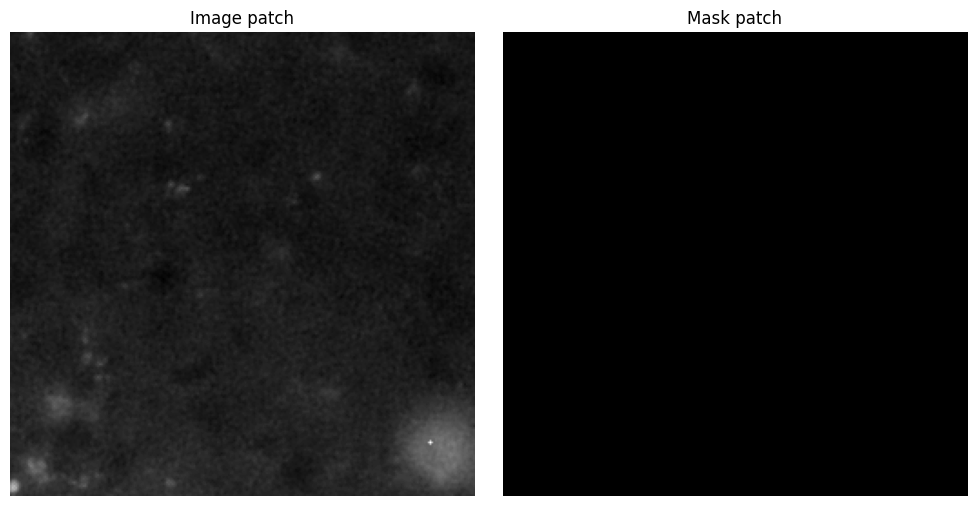

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(image_patch, cmap="gray")
axes[0].set_title("Image patch")
axes[0].axis("off")

axes[1].imshow(mask_patch, cmap="gray")
axes[1].set_title("Mask patch")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [49]:
# Measure neuron vs background patch distribution across all training images
PATCH_SIZE = 256

neuron_patch_count = 0
background_patch_count = 0

for filename in train_files:
    mask = Image.open(os.path.join(TRAIN_MASKS, filename)).convert("L")
    mask_array = np.array(mask)
    
    n_rows = mask_array.shape[0] // PATCH_SIZE
    n_cols = mask_array.shape[1] // PATCH_SIZE
    
    for row in range(n_rows):
        for col in range(n_cols):
            r_start = row * PATCH_SIZE
            c_start = col * PATCH_SIZE
            patch = mask_array[r_start:r_start+PATCH_SIZE, c_start:c_start+PATCH_SIZE]
            
            if patch.any():
                neuron_patch_count += 1
            else:
                background_patch_count += 1

total = neuron_patch_count + background_patch_count
print(f"Total patches: {total}")
print(f"Neuron patches: {neuron_patch_count} ({100*neuron_patch_count/total:.1f}%)")
print(f"Background patches: {background_patch_count} ({100*background_patch_count/total:.1f}%)")

Total patches: 4320
Neuron patches: 1732 (40.1%)
Background patches: 2588 (59.9%)


Total patches: 4320
Mean neuron fraction:   0.0071
Median neuron fraction: 0.0000
Max neuron fraction:    0.1051

Patches with >0% neurons:   1732
Patches with >1% neurons:   1211
Patches with >5% neurons:   65
Patches with >10% neurons:  2


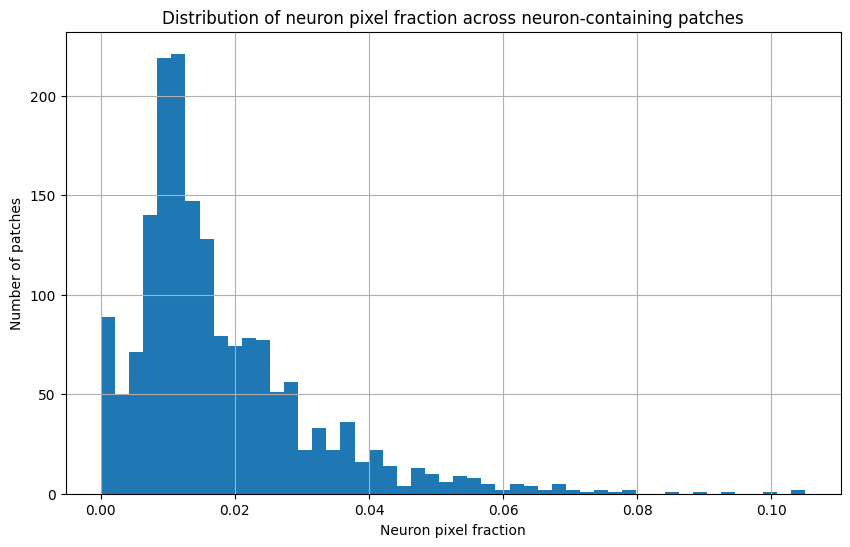

In [50]:
# Measure neuron pixel fraction for every patch across all training images
PATCH_SIZE = 256

neuron_fractions = []

for filename in train_files:
    mask = Image.open(os.path.join(TRAIN_MASKS, filename)).convert("L")
    mask_array = np.array(mask)
    
    n_rows = mask_array.shape[0] // PATCH_SIZE
    n_cols = mask_array.shape[1] // PATCH_SIZE
    
    for row in range(n_rows):
        for col in range(n_cols):
            r_start = row * PATCH_SIZE
            c_start = col * PATCH_SIZE
            patch = mask_array[r_start:r_start+PATCH_SIZE, c_start:c_start+PATCH_SIZE]
            
            # Fraction of pixels that are neuron
            fraction = patch.mean() / 255
            neuron_fractions.append(fraction)

neuron_fractions = np.array(neuron_fractions)

print(f"Total patches: {len(neuron_fractions)}")
print(f"Mean neuron fraction:   {neuron_fractions.mean():.4f}")
print(f"Median neuron fraction: {np.median(neuron_fractions):.4f}")
print(f"Max neuron fraction:    {neuron_fractions.max():.4f}")
print(f"\nPatches with >0% neurons:   {(neuron_fractions > 0).sum()}")
print(f"Patches with >1% neurons:   {(neuron_fractions > 0.01).sum()}")
print(f"Patches with >5% neurons:   {(neuron_fractions > 0.05).sum()}")
print(f"Patches with >10% neurons:  {(neuron_fractions > 0.10).sum()}")

# Plot distribution
plt.figure(figsize=(10, 6))
plt.hist(neuron_fractions[neuron_fractions > 0], bins=50)
plt.xlabel("Neuron pixel fraction")
plt.ylabel("Number of patches")
plt.title("Distribution of neuron pixel fraction across neuron-containing patches")
plt.grid()
plt.show()

In [51]:
# Build a complete patch index for all training images
PATCH_SIZE = 256

patch_index = []

for filename in train_files:
    mask = Image.open(os.path.join(TRAIN_MASKS, filename)).convert("L")
    mask_array = np.array(mask)
    
    n_rows = mask_array.shape[0] // PATCH_SIZE
    n_cols = mask_array.shape[1] // PATCH_SIZE
    
    for row in range(n_rows):
        for col in range(n_cols):
            r_start = row * PATCH_SIZE
            c_start = col * PATCH_SIZE
            patch = mask_array[r_start:r_start+PATCH_SIZE, c_start:c_start+PATCH_SIZE]
            
            neuron_fraction = patch.mean() / 255
            
            # Assign category
            if neuron_fraction == 0:
                category = "background"
            elif neuron_fraction <= 0.05:
                category = "sparse"
            else:
                category = "substantial"
            
            patch_index.append({
                "filename": filename,
                "row": row,
                "col": col,
                "neuron_fraction": neuron_fraction,
                "category": category
            })

# Convert to a summary
import pandas as pd
patch_df = pd.DataFrame(patch_index)

print(patch_df["category"].value_counts())
print(f"\nTotal patches: {len(patch_df)}")
print(patch_df.groupby("category")["neuron_fraction"].describe())

category
background     2588
sparse         1667
substantial      65
Name: count, dtype: int64

Total patches: 4320
              count      mean       std       min       25%       50%  \
category                                                                
background   2588.0  0.000000  0.000000  0.000000  0.000000  0.000000   
sparse       1667.0  0.016007  0.010240  0.000015  0.009079  0.013214   
substantial    65.0  0.063265  0.013262  0.050110  0.053726  0.058823   

                  75%       max  
category                         
background   0.000000  0.000000  
sparse       0.022141  0.049973  
substantial  0.068726  0.105103  


In [52]:
import random
from torch.utils.data import Dataset
import torch
import numpy as np
from PIL import Image
import os

class PatchDataset(Dataset):

    def __init__(self, images_path, masks_path, patch_index, patch_size=256):
        self.images_path = images_path
        self.masks_path = masks_path
        self.patch_size = patch_size
        
        # Store the patch index — list of dicts with filename, row, col, category
        self.patches = patch_index
        
        print(f"PatchDataset ready: {len(self.patches)} patches")

    def __len__(self):
        return len(self.patches)

    def __getitem__(self, idx):
        patch_info = self.patches[idx]
        
        filename = patch_info["filename"]
        row = patch_info["row"]
        col = patch_info["col"]
        
        # Load image and extract green channel
        img = Image.open(os.path.join(self.images_path, filename)).convert("RGB")
        img_array = np.array(img)
        green = img_array[:, :, 1]
        
        # Load mask
        mask = Image.open(os.path.join(self.masks_path, filename)).convert("L")
        mask_array = np.array(mask)
        
        # Extract the correct patch
        r_start = row * self.patch_size
        c_start = col * self.patch_size
        
        img_patch = green[r_start:r_start+self.patch_size, c_start:c_start+self.patch_size]
        mask_patch = mask_array[r_start:r_start+self.patch_size, c_start:c_start+self.patch_size]
        
        # Convert to tensors and normalise
        image_tensor = torch.tensor(img_patch, dtype=torch.float32) / 255.0
        mask_tensor = torch.tensor(mask_patch > 0, dtype=torch.float32)
        
        # Add channel dimension: (H, W) → (1, H, W)
        image_tensor = image_tensor.unsqueeze(0)
        mask_tensor = mask_tensor.unsqueeze(0)
        
        return image_tensor, mask_tensor


# Build sampled training patch list
substantial = patch_df[patch_df["category"] == "substantial"].to_dict("records")
sparse = patch_df[patch_df["category"] == "sparse"].to_dict("records")
background = patch_df[patch_df["category"] == "background"].to_dict("records")

# Sample ~1700 background patches
random.seed(42)
background_sampled = random.sample(background, 1700)

# Combine into training patch list
train_patches = substantial + sparse + background_sampled
random.shuffle(train_patches)

print(f"Substantial: {len(substantial)}")
print(f"Sparse:      {len(sparse)}")
print(f"Background:  {len(background_sampled)}")
print(f"Total training patches: {len(train_patches)}")

# Create the dataset
train_patch_dataset = PatchDataset(TRAIN_IMAGES, TRAIN_MASKS, train_patches)

# Test it
img, mask = train_patch_dataset[0]
print(f"\nImage tensor shape: {img.shape}")
print(f"Mask tensor shape:  {mask.shape}")
print(f"Image range: {img.min():.2f} to {img.max():.2f}")
print(f"Mask values: {mask.unique()}")

Substantial: 65
Sparse:      1667
Background:  1700
Total training patches: 3432
PatchDataset ready: 3432 patches

Image tensor shape: torch.Size([1, 256, 256])
Mask tensor shape:  torch.Size([1, 256, 256])
Image range: 0.10 to 0.64
Mask values: tensor([0., 1.])


In [53]:
import math

PATCH_SIZE = 256

def pad_to_patch_size(array, patch_size=256):
    """Pad a 2D array so both dimensions are multiples of patch_size."""
    h, w = array.shape
    
    # Calculate target dimensions
    new_h = math.ceil(h / patch_size) * patch_size
    new_w = math.ceil(w / patch_size) * patch_size
    
    # Create a zero array of the target size
    padded = np.zeros((new_h, new_w), dtype=array.dtype)
    
    # Place the original array in the top-left
    padded[:h, :w] = array
    
    return padded

# Test on one image
filename = train_files[0]

img = Image.open(os.path.join(TRAIN_IMAGES, filename)).convert("RGB")
img_array = np.array(img)
green = img_array[:, :, 1]

mask = Image.open(os.path.join(TRAIN_MASKS, filename)).convert("L")
mask_array = np.array(mask)

green_padded = pad_to_patch_size(green)
mask_padded = pad_to_patch_size(mask_array)

print(f"Original green shape: {green.shape}")
print(f"Padded green shape:   {green_padded.shape}")
print(f"Patches: {green_padded.shape[0]//PATCH_SIZE} × {green_padded.shape[1]//PATCH_SIZE} = {(green_padded.shape[0]//PATCH_SIZE) * (green_padded.shape[1]//PATCH_SIZE)}")

Original green shape: (1200, 1600)
Padded green shape:   (1280, 1792)
Patches: 5 × 7 = 35


In [54]:
# Rebuild patch index using padded images
padded_patch_index = []

for filename in train_files:
    mask = Image.open(os.path.join(TRAIN_MASKS, filename)).convert("L")
    mask_array = np.array(mask)
    
    # Pad the mask
    mask_padded = pad_to_patch_size(mask_array)
    
    n_rows = mask_padded.shape[0] // PATCH_SIZE
    n_cols = mask_padded.shape[1] // PATCH_SIZE
    
    for row in range(n_rows):
        for col in range(n_cols):
            r_start = row * PATCH_SIZE
            c_start = col * PATCH_SIZE
            patch = mask_padded[r_start:r_start+PATCH_SIZE, c_start:c_start+PATCH_SIZE]
            
            neuron_fraction = patch.mean() / 255
            
            if neuron_fraction == 0:
                category = "background"
            elif neuron_fraction <= 0.05:
                category = "sparse"
            else:
                category = "substantial"
            
            padded_patch_index.append({
                "filename": filename,
                "row": row,
                "col": col,
                "neuron_fraction": neuron_fraction,
                "category": category
            })

padded_patch_df = pd.DataFrame(padded_patch_index)

print(f"Total patches: {len(padded_patch_df)}")
print(f"Expected: 180 × 35 = {180 * 35}")
print()
print(padded_patch_df["category"].value_counts())

Total patches: 6300
Expected: 180 × 35 = 6300

category
background     4249
sparse         1983
substantial      68
Name: count, dtype: int64


In [55]:
# Sample training patches from padded index
substantial_p = padded_patch_df[padded_patch_df["category"] == "substantial"].to_dict("records")
sparse_p = padded_patch_df[padded_patch_df["category"] == "sparse"].to_dict("records")
background_p = padded_patch_df[padded_patch_df["category"] == "background"].to_dict("records")

# Keep all neuron patches, sample background to match
n_neuron = len(substantial_p) + len(sparse_p)
background_sampled_p = random.sample(background_p, n_neuron)

train_patches_padded = substantial_p + sparse_p + background_sampled_p
random.shuffle(train_patches_padded)

print(f"Substantial: {len(substantial_p)}")
print(f"Sparse:      {len(sparse_p)}")
print(f"Background:  {len(background_sampled_p)}")
print(f"Total training patches: {len(train_patches_padded)}")

Substantial: 68
Sparse:      1983
Background:  2051
Total training patches: 4102


In [56]:
class PatchDataset(Dataset):

    def __init__(self, images_path, masks_path, patch_index, patch_size=256):
        self.images_path = images_path
        self.masks_path = masks_path
        self.patch_size = patch_size
        self.patches = patch_index
        print(f"PatchDataset ready: {len(self.patches)} patches")

    def __len__(self):
        return len(self.patches)

    def __getitem__(self, idx):
        patch_info = self.patches[idx]
        
        filename = patch_info["filename"]
        row = patch_info["row"]
        col = patch_info["col"]
        
        # Load image, extract green channel and pad
        img = Image.open(os.path.join(self.images_path, filename)).convert("RGB")
        img_array = np.array(img)
        green = img_array[:, :, 1]
        green_padded = pad_to_patch_size(green, self.patch_size)
        
        # Load mask and pad with zeros (background)
        mask = Image.open(os.path.join(self.masks_path, filename)).convert("L")
        mask_array = np.array(mask)
        mask_padded = pad_to_patch_size(mask_array, self.patch_size)
        
        # Extract the correct patch
        r_start = row * self.patch_size
        c_start = col * self.patch_size
        
        img_patch = green_padded[r_start:r_start+self.patch_size, c_start:c_start+self.patch_size]
        mask_patch = mask_padded[r_start:r_start+self.patch_size, c_start:c_start+self.patch_size]
        
        # Convert to tensors and normalise
        image_tensor = torch.tensor(img_patch, dtype=torch.float32) / 255.0
        mask_tensor = torch.tensor(mask_patch > 0, dtype=torch.float32)
        
        # Add channel dimension: (H, W) → (1, H, W)
        image_tensor = image_tensor.unsqueeze(0)
        mask_tensor = mask_tensor.unsqueeze(0)
        
        return image_tensor, mask_tensor


# Create updated training dataset
train_patch_dataset = PatchDataset(TRAIN_IMAGES, TRAIN_MASKS, train_patches_padded)

# Test it
img, mask = train_patch_dataset[0]
print(f"Image tensor shape: {img.shape}")
print(f"Mask tensor shape:  {mask.shape}")
print(f"Image range: {img.min():.2f} to {img.max():.2f}")
print(f"Mask values: {mask.unique()}")

PatchDataset ready: 4102 patches
Image tensor shape: torch.Size([1, 256, 256])
Mask tensor shape:  torch.Size([1, 256, 256])
Image range: 0.07 to 0.44
Mask values: tensor([0., 1.])


In [57]:
# Test the bottom-right padded patch
last_patch_index = len(train_patch_dataset) - 1

img, mask = train_patch_dataset[last_patch_index]

print(f"Last patch image shape: {img.shape}")
print(f"Last patch mask shape:  {mask.shape}")
print(f"Last patch neuron pixels: {mask.sum().item():.0f}")

Last patch image shape: torch.Size([1, 256, 256])
Last patch mask shape:  torch.Size([1, 256, 256])
Last patch neuron pixels: 0


In [58]:
from torch.utils.data import DataLoader

# Create DataLoaders for training and validation
train_loader = DataLoader(
    train_patch_dataset,
    batch_size=8,
    shuffle=True,
    num_workers=0
)

# Build validation patch index with padding
val_patch_index_padded = []

for filename in val_files:
    mask = Image.open(os.path.join(TRAIN_MASKS, filename)).convert("L")
    mask_array = np.array(mask)
    mask_padded = pad_to_patch_size(mask_array)
    
    n_rows = mask_padded.shape[0] // PATCH_SIZE
    n_cols = mask_padded.shape[1] // PATCH_SIZE
    
    for row in range(n_rows):
        for col in range(n_cols):
            val_patch_index_padded.append({
                "filename": filename,
                "row": row,
                "col": col
            })

val_patch_dataset = PatchDataset(TRAIN_IMAGES, TRAIN_MASKS, val_patch_index_padded)

val_loader = DataLoader(
    val_patch_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

# Check one batch
images, masks = next(iter(train_loader))
print(f"Batch image shape: {images.shape}")
print(f"Batch mask shape:  {masks.shape}")
print(f"Training batches per epoch:   {len(train_loader)}")
print(f"Validation batches per epoch: {len(val_loader)}")

PatchDataset ready: 1120 patches
Batch image shape: torch.Size([8, 1, 256, 256])
Batch mask shape:  torch.Size([8, 1, 256, 256])
Training batches per epoch:   513
Validation batches per epoch: 140


In [59]:
import torch.nn as nn

class DoubleConv(nn.Module):
    """Two consecutive convolution layers, each followed by ReLU.
    This is the repeated building block used throughout U-Net."""
    
    def __init__(self, in_channels, out_channels):
        super().__init__()
        
        self.block = nn.Sequential(
            # First convolution
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            # Second convolution
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True)
        )
    
    def forward(self, x):
        return self.block(x)


# Test it
test_input = torch.zeros(1, 1, 256, 256)
double_conv = DoubleConv(in_channels=1, out_channels=64)
test_output = double_conv(test_input)
print(f"Input shape:  {test_input.shape}")
print(f"Output shape: {test_output.shape}")

Input shape:  torch.Size([1, 1, 256, 256])
Output shape: torch.Size([1, 64, 256, 256])


In [60]:
class UNet(nn.Module):
    
    def __init__(self, in_channels=1, out_channels=1):
        super().__init__()
        
        # --- ENCODER ---
        # Each level: double conv then max pool to halve spatial size
        self.enc1 = DoubleConv(in_channels, 64)
        self.enc2 = DoubleConv(64, 128)
        self.enc3 = DoubleConv(128, 256)
        self.enc4 = DoubleConv(256, 512)
        
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        
        # --- BOTTLENECK ---
        self.bottleneck = DoubleConv(512, 1024)
        
        # --- DECODER ---
        # Each level: upsample then double conv
        # in_channels doubles because we concatenate skip connection
        self.up4 = nn.ConvTranspose2d(1024, 512, kernel_size=2, stride=2)
        self.dec4 = DoubleConv(1024, 512)
        
        self.up3 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.dec3 = DoubleConv(512, 256)
        
        self.up2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.dec2 = DoubleConv(256, 128)
        
        self.up1 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.dec1 = DoubleConv(128, 64)
        
        # --- OUTPUT ---
        # 1×1 convolution to produce final segmentation map
        # Sigmoid squashes output to 0-1 probability per pixel
        self.output = nn.Conv2d(64, out_channels, kernel_size=1)
        self.sigmoid = nn.Sigmoid()
    
    def forward(self, x):
        # Encoder
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        
        # Bottleneck
        b = self.bottleneck(self.pool(e4))
        
        # Decoder with skip connections
        d4 = self.dec4(torch.cat([self.up4(b), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        
        return self.sigmoid(self.output(d1))


# Test the full U-Net
model = UNet(in_channels=1, out_channels=1)

test_input = torch.zeros(1, 1, 256, 256)
test_output = model(test_input)

print(f"Input shape:  {test_input.shape}")
print(f"Output shape: {test_output.shape}")
print(f"Output range: {test_output.min():.3f} to {test_output.max():.3f}")

Input shape:  torch.Size([1, 1, 256, 256])
Output shape: torch.Size([1, 1, 256, 256])
Output range: 0.481 to 0.484


In [61]:
#count how many parameters (weights) the model has 
total_params = sum(p.numel() for p in model.parameters())
print(f"Total parameters: {total_params:,}")

Total parameters: 31,030,593


In [62]:
def dice_loss(pred, target, smooth=1e-6):
    """Dice loss — measures overlap between prediction and target.
    smooth prevents division by zero on empty patches."""
    
    # Flatten both tensors to 1D
    pred_flat = pred.view(-1)
    target_flat = target.view(-1)
    
    # Calculate intersection and union
    intersection = (pred_flat * target_flat).sum()
    dice_score = (2 * intersection + smooth) / (pred_flat.sum() + target_flat.sum() + smooth)
    
    return 1 - dice_score


def combined_loss(pred, target):
    """BCE + Dice loss combined equally."""
    bce = nn.BCELoss()(pred, target)
    dice = dice_loss(pred, target)
    return bce + dice


# Test the loss function
pred = torch.rand(8, 1, 256, 256)
target = torch.randint(0, 2, (8, 1, 256, 256)).float()

loss = combined_loss(pred, target)
print(f"Test loss value: {loss.item():.4f}")

Test loss value: 1.5009


In [63]:
import torch.optim as optim

# Move model to GPU
model = UNet(in_channels=1, out_channels=1).to(device)

# Optimiser — Adam is standard for U-Net
# lr = learning rate, how big each weight update step is
optimizer = optim.Adam(model.parameters(), lr=1e-4)

# Training loop
def train_one_epoch(model, loader, optimizer, device):
    model.train()
    total_loss = 0
    
    for images, masks in loader:
        # Move batch to GPU
        images = images.to(device)
        masks = masks.to(device)
        
        # Forward pass
        predictions = model(images)
        
        # Calculate loss
        loss = combined_loss(predictions, masks)
        
        # Backward pass — calculate gradients
        optimizer.zero_grad()
        loss.backward()
        
        # Update weights
        optimizer.step()
        
        total_loss += loss.item()
    
    return total_loss / len(loader)


def validate(model, loader, device):
    model.eval()
    total_loss = 0
    
    with torch.no_grad():
        for images, masks in loader:
            images = images.to(device)
            masks = masks.to(device)
            
            predictions = model(images)
            loss = combined_loss(predictions, masks)
            total_loss += loss.item()
    
    return total_loss / len(loader)


print("Model moved to:", device)
print("Ready to train")

Model moved to: mps
Ready to train


In [64]:
# Train for 10 epochs to start
NUM_EPOCHS = 10

train_losses = []
val_losses = []

for epoch in range(NUM_EPOCHS):
    
    # Train for one epoch
    train_loss = train_one_epoch(model, train_loader, optimizer, device)
    
    # Evaluate on validation set
    val_loss = validate(model, val_loader, device)
    
    # Store losses
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    
    print(f"Epoch {epoch+1}/{NUM_EPOCHS} — Train loss: {train_loss:.4f} | Val loss: {val_loss:.4f}")

# Plot loss curves
plt.figure(figsize=(10, 6))
plt.plot(train_losses, label="Train loss")
plt.plot(val_losses, label="Val loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and validation loss")
plt.legend()
plt.grid()
plt.show()

KeyboardInterrupt: 

In [ ]:
class PreloadedPatchDataset(Dataset):
    """Loads all patches into memory at initialisation.
    Much faster than loading from disk during training."""
    
    def __init__(self, images_path, masks_path, patch_index, patch_size=256):
        self.patch_size = patch_size
        self.image_patches = []
        self.mask_patches = []
        
        print("Preloading patches into memory...")
        
        for patch_info in patch_index:
            filename = patch_info["filename"]
            row = patch_info["row"]
            col = patch_info["col"]
            
            img = Image.open(os.path.join(images_path, filename)).convert("RGB")
            img_array = np.array(img)
            green = img_array[:, :, 1]
            green_padded = pad_to_patch_size(green, patch_size)
            
            mask = Image.open(os.path.join(masks_path, filename)).convert("L")
            mask_array = np.array(mask)
            mask_padded = pad_to_patch_size(mask_array, patch_size)
            
            r_start = row * patch_size
            c_start = col * patch_size
            
            img_patch = green_padded[r_start:r_start+patch_size, c_start:c_start+patch_size]
            mask_patch = mask_padded[r_start:r_start+patch_size, c_start:c_start+patch_size]
            
            image_tensor = torch.tensor(img_patch, dtype=torch.float32) / 255.0
            mask_tensor = torch.tensor(mask_patch > 0, dtype=torch.float32)
            
            self.image_patches.append(image_tensor.unsqueeze(0))
            self.mask_patches.append(mask_tensor.unsqueeze(0))
        
        print(f"Preloaded {len(self.image_patches)} patches")

    def __len__(self):
        return len(self.image_patches)

    def __getitem__(self, idx):
        return self.image_patches[idx], self.mask_patches[idx]


# Preload training patches
train_patch_dataset_fast = PreloadedPatchDataset(TRAIN_IMAGES, TRAIN_MASKS, train_patches_padded)
val_patch_dataset_fast = PreloadedPatchDataset(TRAIN_IMAGES, TRAIN_MASKS, val_patch_index_padded)

# Rebuild DataLoaders
train_loader = DataLoader(train_patch_dataset_fast, batch_size=8, shuffle=True)
val_loader = DataLoader(val_patch_dataset_fast, batch_size=8, shuffle=False)

print(f"Training batches: {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")

Preloading patches into memory...
Preloaded 4102 patches
Preloading patches into memory...
Preloaded 1120 patches
Training batches: 513
Validation batches: 140


In [ ]:
# Reinitialise model and optimiser fresh
model = UNet(in_channels=1, out_channels=1).to(device)
optimizer = optim.Adam(model.parameters(), lr=1e-4)

# Train for 10 epochs
NUM_EPOCHS = 10
train_losses = []
val_losses = []

for epoch in range(NUM_EPOCHS):
    train_loss = train_one_epoch(model, train_loader, optimizer, device)
    val_loss = validate(model, val_loader, device)
    
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    
    print(f"Epoch {epoch+1}/{NUM_EPOCHS} — Train loss: {train_loss:.4f} | Val loss: {val_loss:.4f}")

Epoch 1/10 — Train loss: 0.7701 | Val loss: 0.6038
Epoch 2/10 — Train loss: 0.4139 | Val loss: 0.5617
Epoch 3/10 — Train loss: 0.3915 | Val loss: 0.5661
Epoch 4/10 — Train loss: 0.3673 | Val loss: 0.5437
Epoch 5/10 — Train loss: 0.3673 | Val loss: 0.5525
Epoch 6/10 — Train loss: 0.3530 | Val loss: 0.5749
Epoch 7/10 — Train loss: 0.3652 | Val loss: 0.5505
Epoch 8/10 — Train loss: 0.3483 | Val loss: 0.5395
Epoch 9/10 — Train loss: 0.3361 | Val loss: 0.5309
Epoch 10/10 — Train loss: 0.3326 | Val loss: 0.5453


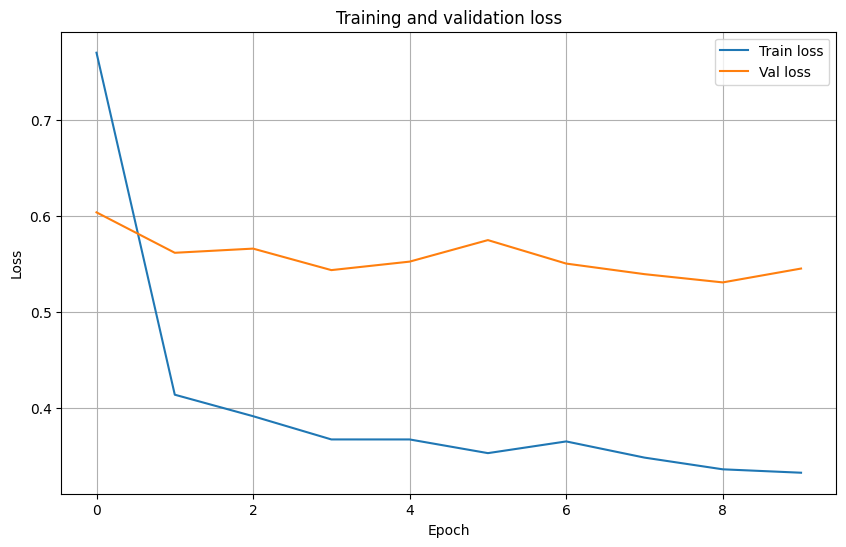

In [ ]:
# Plot loss curves
plt.figure(figsize=(10, 6))
plt.plot(train_losses, label="Train loss")
plt.plot(val_losses, label="Val loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and validation loss")
plt.legend()
plt.grid()
plt.show()

In [ ]:
# Save the trained model
torch.save(model.state_dict(), "unet_epoch10.pth")
print("Model saved")

Model saved


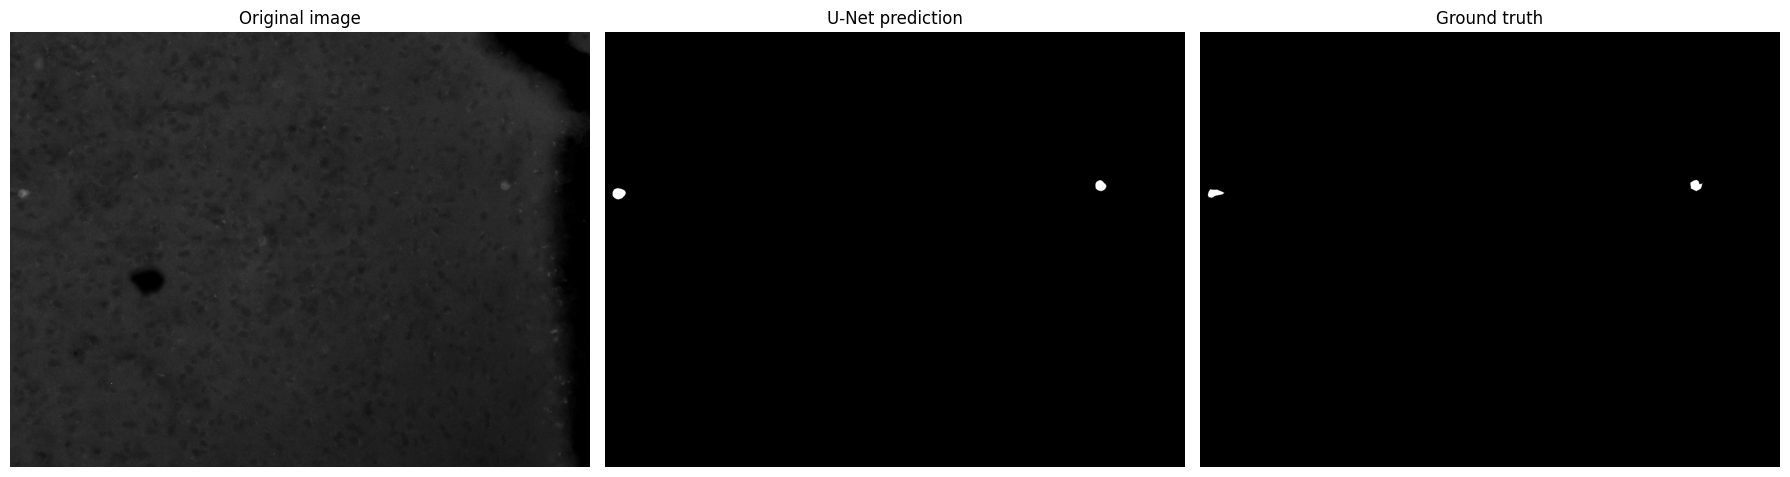

Dice score for 168.png: 0.856


In [ ]:
# Load the saved model
model.load_state_dict(torch.load("unet_epoch10.pth"))
model.eval()

# Pick a validation image and run predictions on all its patches
filename = val_files[0]

img = Image.open(os.path.join(TRAIN_IMAGES, filename)).convert("RGB")
img_array = np.array(img)
green = img_array[:, :, 1]
green_padded = pad_to_patch_size(green)

mask = Image.open(os.path.join(TRAIN_MASKS, filename)).convert("L")
mask_array = np.array(mask)

# Build full prediction by running each patch through the model
n_rows = green_padded.shape[0] // PATCH_SIZE
n_cols = green_padded.shape[1] // PATCH_SIZE

prediction_canvas = np.zeros_like(green_padded, dtype=np.float32)

with torch.no_grad():
    for row in range(n_rows):
        for col in range(n_cols):
            r_start = row * PATCH_SIZE
            c_start = col * PATCH_SIZE
            
            patch = green_padded[r_start:r_start+PATCH_SIZE, c_start:c_start+PATCH_SIZE]
            
            tensor = torch.tensor(patch, dtype=torch.float32) / 255.0
            tensor = tensor.unsqueeze(0).unsqueeze(0).to(device)
            
            pred = model(tensor)
            prediction_canvas[r_start:r_start+PATCH_SIZE, c_start:c_start+PATCH_SIZE] = pred.squeeze().cpu().numpy()

# Crop back to original size
prediction = prediction_canvas[:1200, :1600]
binary_prediction = (prediction > 0.5).astype(np.uint8)

# Display
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(green, cmap="gray")
axes[0].set_title("Original image")
axes[0].axis("off")

axes[1].imshow(binary_prediction, cmap="gray")
axes[1].set_title("U-Net prediction")
axes[1].axis("off")

axes[2].imshow(mask_array, cmap="gray")
axes[2].set_title("Ground truth")
axes[2].axis("off")

plt.tight_layout()
plt.show()

# Calculate Dice
gt_binary = (mask_array > 0).astype(np.uint8)
tp = np.sum((binary_prediction == 1) & (gt_binary == 1))
fp = np.sum((binary_prediction == 1) & (gt_binary == 0))
fn = np.sum((binary_prediction == 0) & (gt_binary == 1))
dice = (2 * tp) / (2 * tp + fp + fn) if (2 * tp + fp + fn) > 0 else 0
print(f"Dice score for {filename}: {dice:.3f}")

In [ ]:
# Evaluate U-Net across all validation images
val_dice_scores = []

model.eval()

for filename in val_files:
    img = Image.open(os.path.join(TRAIN_IMAGES, filename)).convert("RGB")
    img_array = np.array(img)
    green = img_array[:, :, 1]
    green_padded = pad_to_patch_size(green)

    mask = Image.open(os.path.join(TRAIN_MASKS, filename)).convert("L")
    mask_array = np.array(mask)

    n_rows = green_padded.shape[0] // PATCH_SIZE
    n_cols = green_padded.shape[1] // PATCH_SIZE
    prediction_canvas = np.zeros_like(green_padded, dtype=np.float32)

    with torch.no_grad():
        for row in range(n_rows):
            for col in range(n_cols):
                r_start = row * PATCH_SIZE
                c_start = col * PATCH_SIZE
                patch = green_padded[r_start:r_start+PATCH_SIZE, c_start:c_start+PATCH_SIZE]
                tensor = torch.tensor(patch, dtype=torch.float32) / 255.0
                tensor = tensor.unsqueeze(0).unsqueeze(0).to(device)
                pred = model(tensor)
                prediction_canvas[r_start:r_start+PATCH_SIZE, c_start:c_start+PATCH_SIZE] = pred.squeeze().cpu().numpy()

    prediction = prediction_canvas[:1200, :1600]
    binary_prediction = (prediction > 0.5).astype(np.uint8)
    gt_binary = (mask_array > 0).astype(np.uint8)

    tp = np.sum((binary_prediction == 1) & (gt_binary == 1))
    fp = np.sum((binary_prediction == 1) & (gt_binary == 0))
    fn = np.sum((binary_prediction == 0) & (gt_binary == 1))
    dice = (2 * tp) / (2 * tp + fp + fn) if (2 * tp + fp + fn) > 0 else 0
    val_dice_scores.append(dice)

print(f"Mean Dice across 32 validation images: {np.mean(val_dice_scores):.3f}")
print(f"Median: {np.median(val_dice_scores):.3f}")
print(f"Std:    {np.std(val_dice_scores):.3f}")
print(f"Best:  {np.max(val_dice_scores):.3f}")
print(f"Worst: {np.min(val_dice_scores):.3f}")

Mean Dice across 32 validation images: 0.612
Median: 0.629
Std:    0.166
Best:  0.865
Worst: 0.211


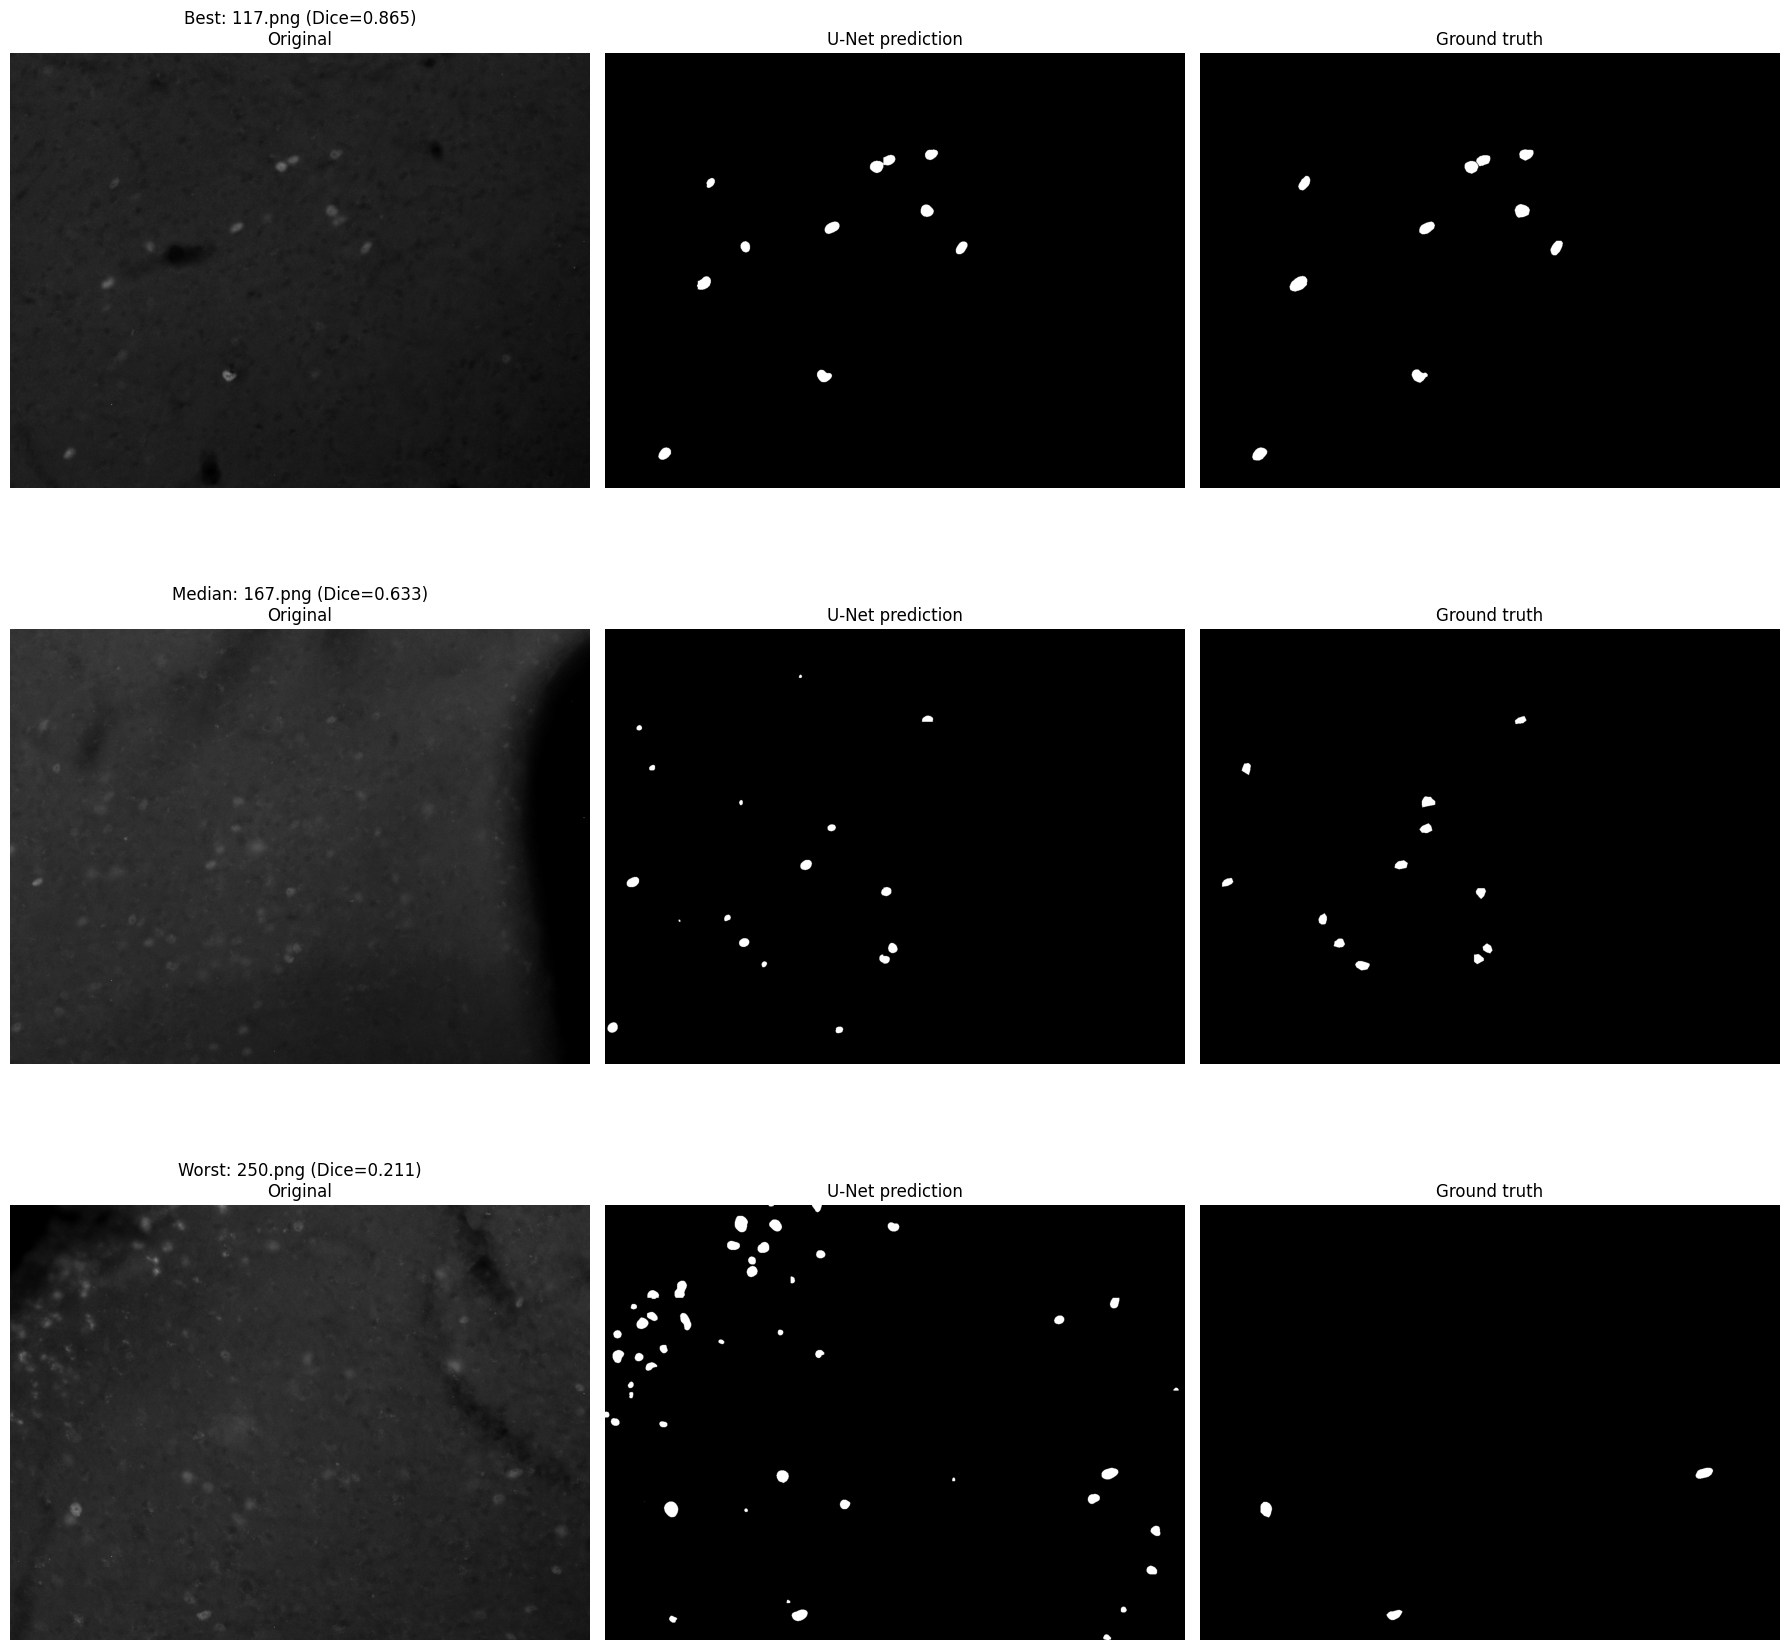

In [ ]:
# Find best, median and worst images
val_dice_array = np.array(val_dice_scores)
best_idx = np.argmax(val_dice_array)
worst_idx = np.argmin(val_dice_array)
median_idx = np.argsort(val_dice_array)[len(val_dice_array)//2]

indices_to_show = [best_idx, median_idx, worst_idx]
labels = ["Best", "Median", "Worst"]

fig, axes = plt.subplots(3, 3, figsize=(18, 18))

for i, (idx, label) in enumerate(zip(indices_to_show, labels)):
    filename = val_files[idx]
    dice = val_dice_array[idx]
    
    # Load and predict
    img = Image.open(os.path.join(TRAIN_IMAGES, filename)).convert("RGB")
    img_array = np.array(img)
    green = img_array[:, :, 1]
    green_padded = pad_to_patch_size(green)
    
    mask = Image.open(os.path.join(TRAIN_MASKS, filename)).convert("L")
    mask_array = np.array(mask)
    
    n_rows = green_padded.shape[0] // PATCH_SIZE
    n_cols = green_padded.shape[1] // PATCH_SIZE
    prediction_canvas = np.zeros_like(green_padded, dtype=np.float32)
    
    with torch.no_grad():
        for row in range(n_rows):
            for col in range(n_cols):
                r_start = row * PATCH_SIZE
                c_start = col * PATCH_SIZE
                patch = green_padded[r_start:r_start+PATCH_SIZE, c_start:c_start+PATCH_SIZE]
                tensor = torch.tensor(patch, dtype=torch.float32) / 255.0
                tensor = tensor.unsqueeze(0).unsqueeze(0).to(device)
                pred = model(tensor)
                prediction_canvas[r_start:r_start+PATCH_SIZE, c_start:c_start+PATCH_SIZE] = pred.squeeze().cpu().numpy()
    
    prediction = prediction_canvas[:1200, :1600]
    binary_prediction = (prediction > 0.5).astype(np.uint8)
    
    # Plot
    axes[i, 0].imshow(green, cmap="gray")
    axes[i, 0].set_title(f"{label}: {filename} (Dice={dice:.3f})\nOriginal")
    axes[i, 0].axis("off")
    
    axes[i, 1].imshow(binary_prediction, cmap="gray")
    axes[i, 1].set_title("U-Net prediction")
    axes[i, 1].axis("off")
    
    axes[i, 2].imshow(mask_array, cmap="gray")
    axes[i, 2].set_title("Ground truth")
    axes[i, 2].axis("off")

plt.tight_layout()
plt.show()

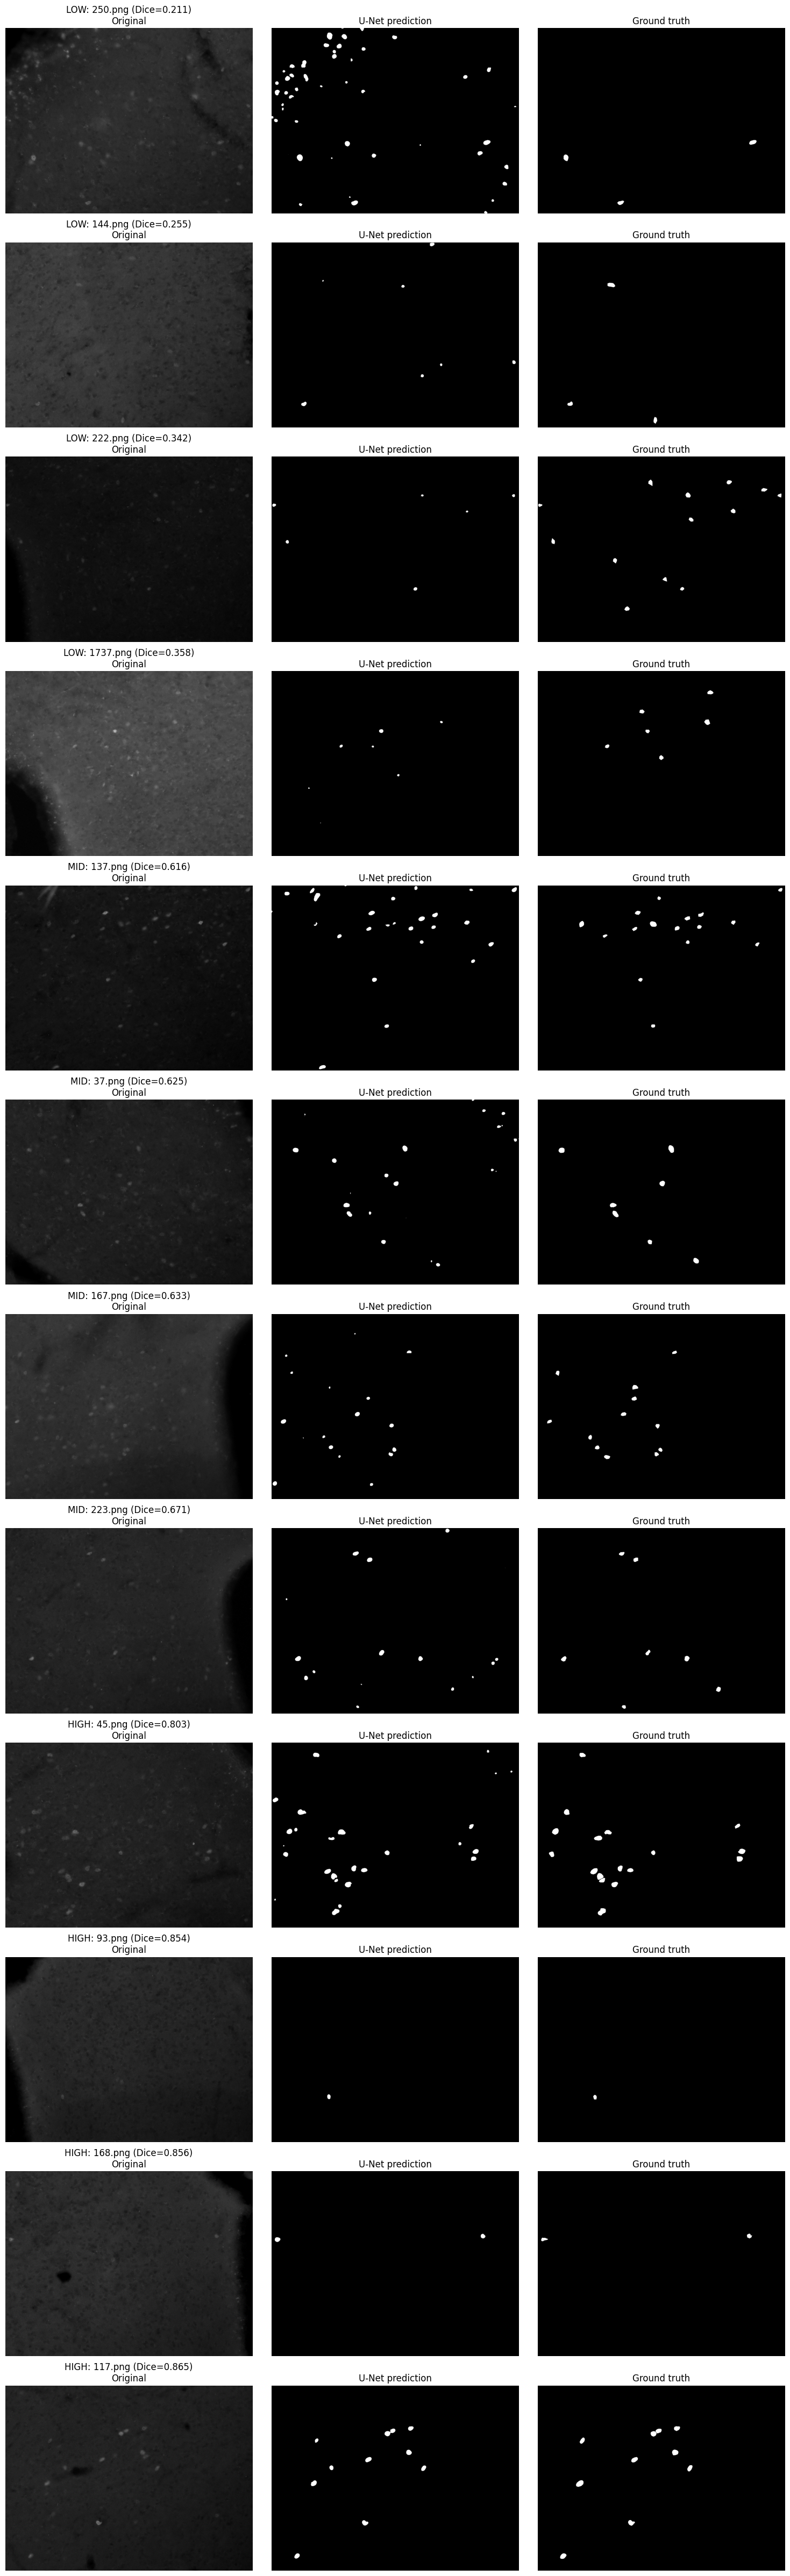

In [ ]:
# Generate gallery of 12 validation images across the Dice score range
# Pick 4 low, 4 middle, 4 high scoring images
val_dice_array = np.array(val_dice_scores)
sorted_indices = np.argsort(val_dice_array)

low_indices = sorted_indices[:4]        # 4 worst
mid_indices = sorted_indices[14:18]     # 4 middle
high_indices = sorted_indices[-4:]      # 4 best

gallery_indices = list(low_indices) + list(mid_indices) + list(high_indices)

fig, axes = plt.subplots(12, 3, figsize=(15, 48))

for plot_row, idx in enumerate(gallery_indices):
    filename = val_files[idx]
    dice = val_dice_array[idx]
    
    # Load and predict
    img = Image.open(os.path.join(TRAIN_IMAGES, filename)).convert("RGB")
    img_array = np.array(img)
    green = img_array[:, :, 1]
    green_padded = pad_to_patch_size(green)
    
    mask = Image.open(os.path.join(TRAIN_MASKS, filename)).convert("L")
    mask_array = np.array(mask)
    
    n_rows = green_padded.shape[0] // PATCH_SIZE
    n_cols = green_padded.shape[1] // PATCH_SIZE
    prediction_canvas = np.zeros_like(green_padded, dtype=np.float32)
    
    with torch.no_grad():
        for row in range(n_rows):
            for col in range(n_cols):
                r_start = row * PATCH_SIZE
                c_start = col * PATCH_SIZE
                patch = green_padded[r_start:r_start+PATCH_SIZE, c_start:c_start+PATCH_SIZE]
                tensor = torch.tensor(patch, dtype=torch.float32) / 255.0
                tensor = tensor.unsqueeze(0).unsqueeze(0).to(device)
                pred = model(tensor)
                prediction_canvas[r_start:r_start+PATCH_SIZE, c_start:c_start+PATCH_SIZE] = pred.squeeze().cpu().numpy()
    
    prediction = prediction_canvas[:1200, :1600]
    binary_prediction = (prediction > 0.5).astype(np.uint8)
    
    # Label by group
    if plot_row < 4:
        group = "LOW"
    elif plot_row < 8:
        group = "MID"
    else:
        group = "HIGH"
    
    axes[plot_row, 0].imshow(green, cmap="gray")
    axes[plot_row, 0].set_title(f"{group}: {filename} (Dice={dice:.3f})\nOriginal")
    axes[plot_row, 0].axis("off")
    
    axes[plot_row, 1].imshow(binary_prediction, cmap="gray")
    axes[plot_row, 1].set_title("U-Net prediction")
    axes[plot_row, 1].axis("off")
    
    axes[plot_row, 2].imshow(mask_array, cmap="gray")
    axes[plot_row, 2].set_title("Ground truth")
    axes[plot_row, 2].axis("off")

plt.tight_layout()
plt.show()

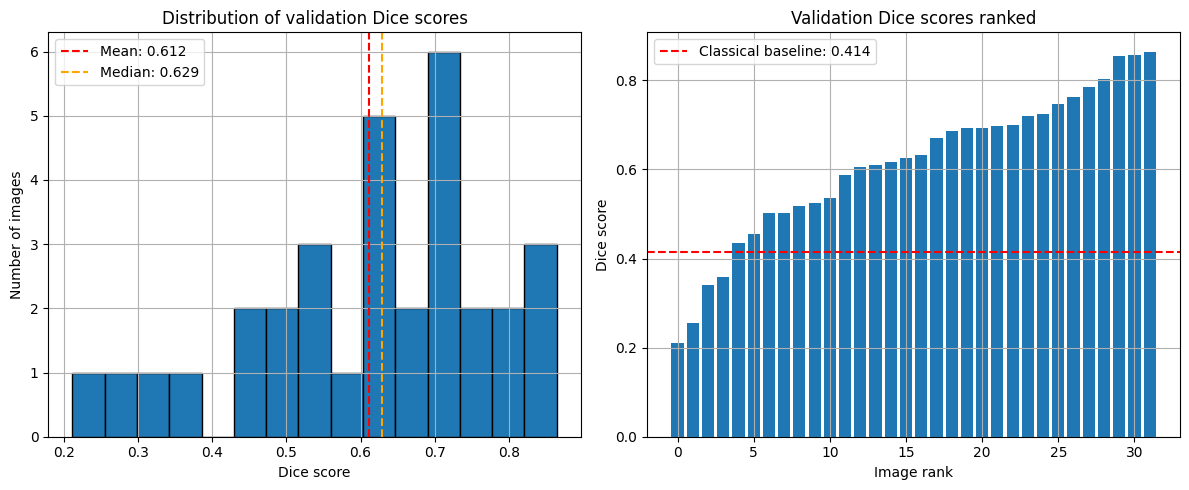

In [ ]:
# Plot distribution of validation Dice scores
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(val_dice_scores, bins=15, edgecolor='black')
plt.xlabel("Dice score")
plt.ylabel("Number of images")
plt.title("Distribution of validation Dice scores")
plt.axvline(np.mean(val_dice_scores), color='red', linestyle='--', label=f'Mean: {np.mean(val_dice_scores):.3f}')
plt.axvline(np.median(val_dice_scores), color='orange', linestyle='--', label=f'Median: {np.median(val_dice_scores):.3f}')
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
sorted_scores = sorted(val_dice_scores)
plt.bar(range(len(sorted_scores)), sorted_scores)
plt.xlabel("Image rank")
plt.ylabel("Dice score")
plt.title("Validation Dice scores ranked")
plt.axhline(0.414, color='red', linestyle='--', label='Classical baseline: 0.414')
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

In [65]:
import random

class AugmentedPatchDataset(Dataset):
    """Same as PatchDataset but applies random augmentations during training."""
    
    def __init__(self, images_path, masks_path, patch_index, patch_size=256, augment=True):
        self.images_path = images_path
        self.masks_path = masks_path
        self.patch_size = patch_size
        self.augment = augment
        self.image_patches = []
        self.mask_patches = []
        
        print("Preloading patches into memory...")
        
        for patch_info in patch_index:
            filename = patch_info["filename"]
            row = patch_info["row"]
            col = patch_info["col"]
            
            img = Image.open(os.path.join(images_path, filename)).convert("RGB")
            img_array = np.array(img)
            green = img_array[:, :, 1]
            green_padded = pad_to_patch_size(green, patch_size)
            
            mask = Image.open(os.path.join(masks_path, filename)).convert("L")
            mask_array = np.array(mask)
            mask_padded = pad_to_patch_size(mask_array, patch_size)
            
            r_start = row * patch_size
            c_start = col * patch_size
            
            img_patch = green_padded[r_start:r_start+patch_size, c_start:c_start+patch_size]
            mask_patch = mask_padded[r_start:r_start+patch_size, c_start:c_start+patch_size]
            
            # Store as numpy arrays — augmentation applied at retrieval time
            self.image_patches.append(img_patch)
            self.mask_patches.append(mask_patch)
        
        print(f"Preloaded {len(self.image_patches)} patches")

    def __len__(self):
        return len(self.image_patches)

    def __getitem__(self, idx):
        img_patch = self.image_patches[idx].copy()
        mask_patch = self.mask_patches[idx].copy()
        
        if self.augment:
            # Horizontal flip
            if random.random() > 0.5:
                img_patch = np.fliplr(img_patch)
                mask_patch = np.fliplr(mask_patch)
            
            # Vertical flip
            if random.random() > 0.5:
                img_patch = np.flipud(img_patch)
                mask_patch = np.flipud(mask_patch)
            
            # 90 degree rotation (0, 90, 180, 270)
            k = random.randint(0, 3)
            img_patch = np.rot90(img_patch, k)
            mask_patch = np.rot90(mask_patch, k)
            
            # Brightness variation — multiply by random factor
            # Addresses both dim neuron and bright background failure modes
            brightness_factor = random.uniform(0.7, 1.3)
            img_patch = np.clip(img_patch * brightness_factor, 0, 255)
            
            # Gaussian noise
            noise = np.random.normal(0, 5, img_patch.shape)
            img_patch = np.clip(img_patch + noise, 0, 255)
        
        # Convert to tensors
        image_tensor = torch.tensor(img_patch.copy(), dtype=torch.float32) / 255.0
        mask_tensor = torch.tensor(mask_patch.copy() > 0, dtype=torch.float32)
        
        image_tensor = image_tensor.unsqueeze(0)
        mask_tensor = mask_tensor.unsqueeze(0)
        
        return image_tensor, mask_tensor


# Create augmented training dataset
train_augmented = AugmentedPatchDataset(TRAIN_IMAGES, TRAIN_MASKS, train_patches_padded, augment=True)

# Validation gets no augmentation
val_no_aug = AugmentedPatchDataset(TRAIN_IMAGES, TRAIN_MASKS, val_patch_index_padded, augment=False)

# Rebuild DataLoaders
train_loader_v2 = DataLoader(train_augmented, batch_size=8, shuffle=True)
val_loader_v2 = DataLoader(val_no_aug, batch_size=8, shuffle=False)

print(f"Training batches: {len(train_loader_v2)}")
print(f"Validation batches: {len(val_loader_v2)}")

Preloading patches into memory...
Preloaded 4102 patches
Preloading patches into memory...
Preloaded 1120 patches
Training batches: 513
Validation batches: 140


In [66]:
# Train U-Net v2 with augmentation
model_v2 = UNet(in_channels=1, out_channels=1).to(device)
optimizer_v2 = optim.Adam(model_v2.parameters(), lr=1e-4)

NUM_EPOCHS = 10
train_losses_v2 = []
val_losses_v2 = []

for epoch in range(NUM_EPOCHS):
    train_loss = train_one_epoch(model_v2, train_loader_v2, optimizer_v2, device)
    val_loss = validate(model_v2, val_loader_v2, device)
    
    train_losses_v2.append(train_loss)
    val_losses_v2.append(val_loss)
    
    print(f"Epoch {epoch+1}/{NUM_EPOCHS} — Train loss: {train_loss:.4f} | Val loss: {val_loss:.4f}")

# Save v2
torch.save(model_v2.state_dict(), "unet_v2_augmented.pth")
print("Model v2 saved")

Epoch 1/10 — Train loss: 1.0143 | Val loss: 0.8036
Epoch 2/10 — Train loss: 0.5458 | Val loss: 0.6074
Epoch 3/10 — Train loss: 0.4558 | Val loss: 0.5789
Epoch 4/10 — Train loss: 0.4307 | Val loss: 0.5603
Epoch 5/10 — Train loss: 0.4769 | Val loss: 0.5870
Epoch 6/10 — Train loss: 0.4216 | Val loss: 0.5572
Epoch 7/10 — Train loss: 0.4104 | Val loss: 0.5490
Epoch 8/10 — Train loss: 0.3938 | Val loss: 0.5501
Epoch 9/10 — Train loss: 0.3826 | Val loss: 0.5480
Epoch 10/10 — Train loss: 0.3713 | Val loss: 0.5461
Model v2 saved


In [67]:
# Load v2 model
model_v2.load_state_dict(torch.load("unet_v2_augmented.pth"))
model_v2.eval()

val_dice_scores_v2 = []

for filename in val_files:
    img = Image.open(os.path.join(TRAIN_IMAGES, filename)).convert("RGB")
    img_array = np.array(img)
    green = img_array[:, :, 1]
    green_padded = pad_to_patch_size(green)

    mask = Image.open(os.path.join(TRAIN_MASKS, filename)).convert("L")
    mask_array = np.array(mask)

    n_rows = green_padded.shape[0] // PATCH_SIZE
    n_cols = green_padded.shape[1] // PATCH_SIZE
    prediction_canvas = np.zeros_like(green_padded, dtype=np.float32)

    with torch.no_grad():
        for row in range(n_rows):
            for col in range(n_cols):
                r_start = row * PATCH_SIZE
                c_start = col * PATCH_SIZE
                patch = green_padded[r_start:r_start+PATCH_SIZE, c_start:c_start+PATCH_SIZE]
                tensor = torch.tensor(patch, dtype=torch.float32) / 255.0
                tensor = tensor.unsqueeze(0).unsqueeze(0).to(device)
                pred = model_v2(tensor)
                prediction_canvas[r_start:r_start+PATCH_SIZE, c_start:c_start+PATCH_SIZE] = pred.squeeze().cpu().numpy()

    prediction = prediction_canvas[:1200, :1600]
    binary_prediction = (prediction > 0.5).astype(np.uint8)
    gt_binary = (mask_array > 0).astype(np.uint8)

    tp = np.sum((binary_prediction == 1) & (gt_binary == 1))
    fp = np.sum((binary_prediction == 1) & (gt_binary == 0))
    fn = np.sum((binary_prediction == 0) & (gt_binary == 1))
    dice = (2 * tp) / (2 * tp + fp + fn) if (2 * tp + fp + fn) > 0 else 0
    val_dice_scores_v2.append(dice)

print(f"V1 Mean Dice: 0.612")
print(f"V2 Mean Dice: {np.mean(val_dice_scores_v2):.3f}")
print(f"V2 Median:    {np.median(val_dice_scores_v2):.3f}")
print(f"V2 Std:       {np.std(val_dice_scores_v2):.3f}")
print(f"V2 Best:      {np.max(val_dice_scores_v2):.3f}")
print(f"V2 Worst:     {np.min(val_dice_scores_v2):.3f}")

V1 Mean Dice: 0.612
V2 Mean Dice: 0.622
V2 Median:    0.649
V2 Std:       0.140
V2 Best:      0.809
V2 Worst:     0.356


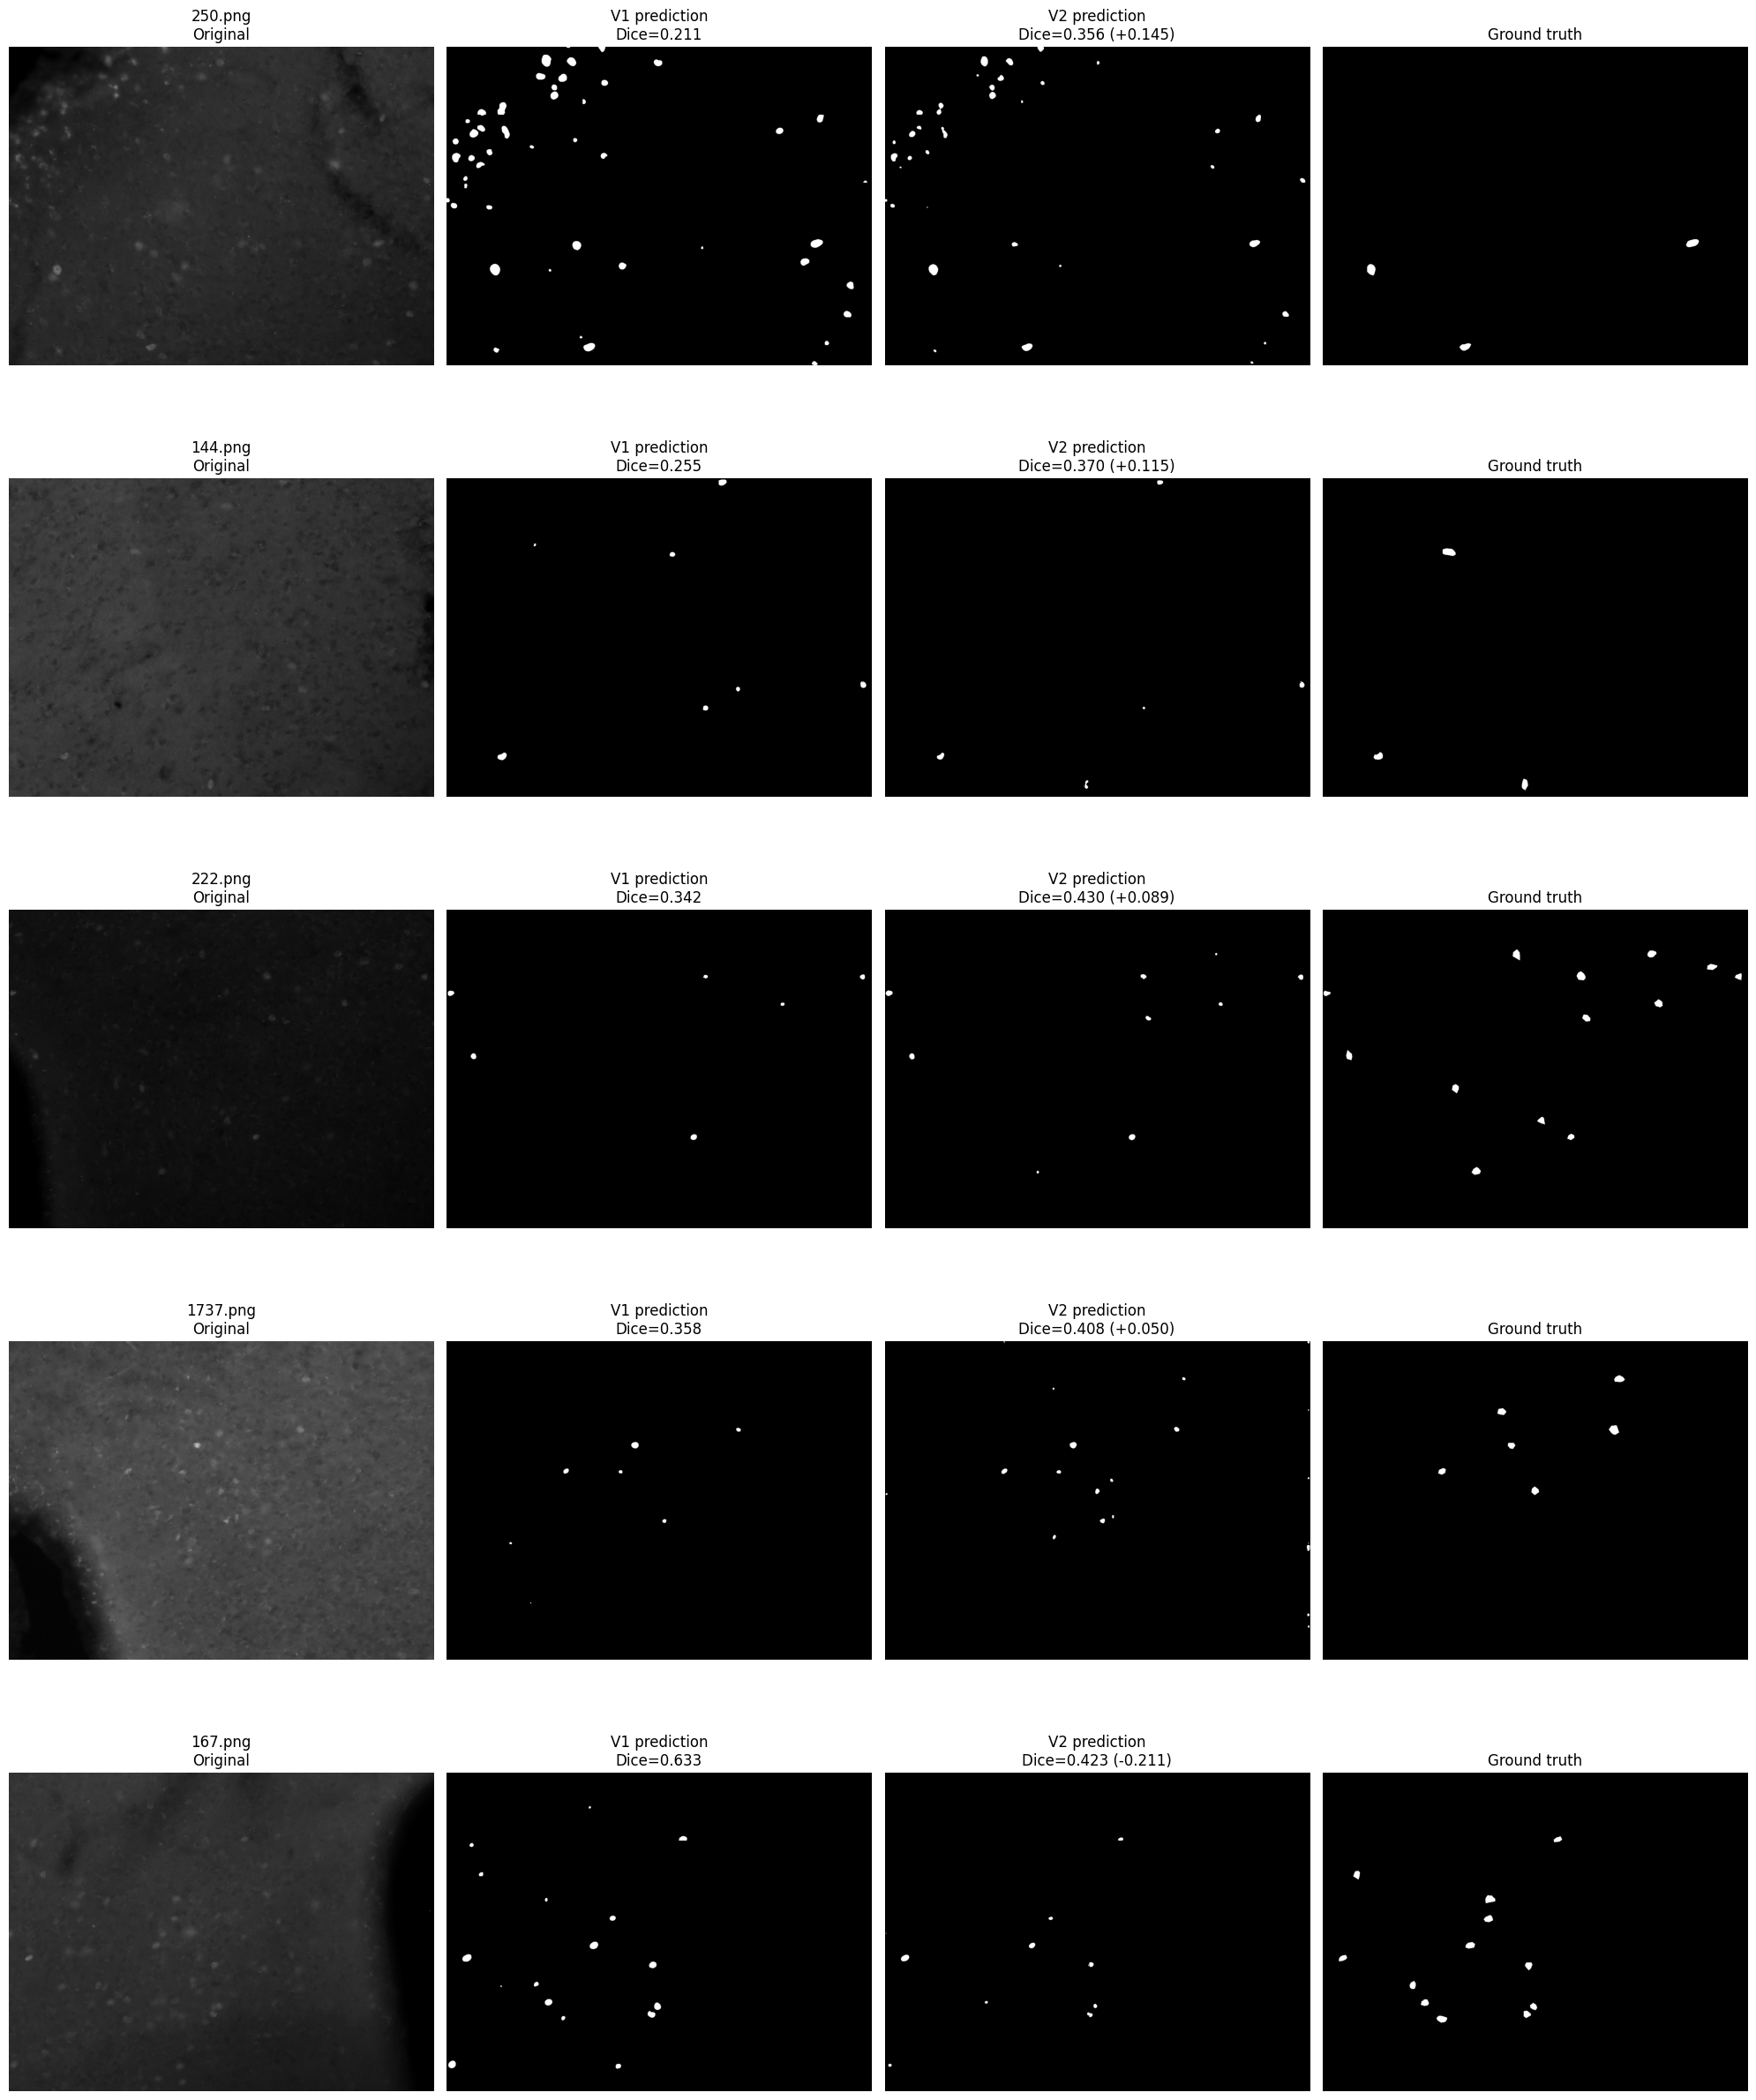

In [68]:
# Compare V1 vs V2 on the five images we already inspected
target_files = ["250.png", "144.png", "222.png", "1737.png", "167.png"]

# Load both models
model_v1 = UNet(in_channels=1, out_channels=1).to(device)
model_v1.load_state_dict(torch.load("unet_epoch10.pth"))
model_v1.eval()

model_v2.load_state_dict(torch.load("unet_v2_augmented.pth"))
model_v2.eval()

fig, axes = plt.subplots(5, 4, figsize=(20, 25))

for i, filename in enumerate(target_files):
    img = Image.open(os.path.join(TRAIN_IMAGES, filename)).convert("RGB")
    img_array = np.array(img)
    green = img_array[:, :, 1]
    green_padded = pad_to_patch_size(green)
    
    mask = Image.open(os.path.join(TRAIN_MASKS, filename)).convert("L")
    mask_array = np.array(mask)
    gt_binary = (mask_array > 0).astype(np.uint8)
    
    n_rows = green_padded.shape[0] // PATCH_SIZE
    n_cols = green_padded.shape[1] // PATCH_SIZE
    
    predictions = {}
    
    for model, name in [(model_v1, "v1"), (model_v2, "v2")]:
        canvas = np.zeros_like(green_padded, dtype=np.float32)
        with torch.no_grad():
            for row in range(n_rows):
                for col in range(n_cols):
                    r_start = row * PATCH_SIZE
                    c_start = col * PATCH_SIZE
                    patch = green_padded[r_start:r_start+PATCH_SIZE, c_start:c_start+PATCH_SIZE]
                    tensor = torch.tensor(patch, dtype=torch.float32) / 255.0
                    tensor = tensor.unsqueeze(0).unsqueeze(0).to(device)
                    pred = model(tensor)
                    canvas[r_start:r_start+PATCH_SIZE, c_start:c_start+PATCH_SIZE] = pred.squeeze().cpu().numpy()
        
        prediction = (canvas[:1200, :1600] > 0.5).astype(np.uint8)
        predictions[name] = prediction
        
        tp = np.sum((prediction == 1) & (gt_binary == 1))
        fp = np.sum((prediction == 1) & (gt_binary == 0))
        fn = np.sum((prediction == 0) & (gt_binary == 1))
        dice = (2 * tp) / (2 * tp + fp + fn) if (2 * tp + fp + fn) > 0 else 0
        predictions[f"{name}_dice"] = dice
    
    v1_dice = predictions["v1_dice"]
    v2_dice = predictions["v2_dice"]
    change = v2_dice - v1_dice
    
    axes[i, 0].imshow(green, cmap="gray")
    axes[i, 0].set_title(f"{filename}\nOriginal")
    axes[i, 0].axis("off")
    
    axes[i, 1].imshow(predictions["v1"], cmap="gray")
    axes[i, 1].set_title(f"V1 prediction\nDice={v1_dice:.3f}")
    axes[i, 1].axis("off")
    
    axes[i, 2].imshow(predictions["v2"], cmap="gray")
    axes[i, 2].set_title(f"V2 prediction\nDice={v2_dice:.3f} ({'+' if change>0 else ''}{change:.3f})")
    axes[i, 2].axis("off")
    
    axes[i, 3].imshow(mask_array, cmap="gray")
    axes[i, 3].set_title("Ground truth")
    axes[i, 3].axis("off")

plt.tight_layout()
plt.show()

In [69]:
def get_probability_map(model, filename, images_path, device, patch_size=256):
    """
    Run a trained model over a full image and return the raw
    probability map before thresholding.
    """
    img = Image.open(os.path.join(images_path, filename)).convert("RGB")
    img_array = np.array(img)
    green = img_array[:, :, 1]
    original_height, original_width = green.shape
    green_padded = pad_to_patch_size(green, patch_size)
    n_rows = green_padded.shape[0] // patch_size
    n_cols = green_padded.shape[1] // patch_size
    canvas = np.zeros_like(green_padded, dtype=np.float32)

    with torch.no_grad():
        for row in range(n_rows):
            for col in range(n_cols):
                r_start = row * patch_size
                c_start = col * patch_size
                patch = green_padded[r_start:r_start+patch_size, c_start:c_start+patch_size]
                tensor = torch.tensor(patch, dtype=torch.float32) / 255.0
                tensor = tensor.unsqueeze(0).unsqueeze(0).to(device)
                pred = model(tensor)
                canvas[r_start:r_start+patch_size, c_start:c_start+patch_size] = pred.squeeze().cpu().numpy()

    return canvas[:original_height, :original_width]


# Precompute probability maps for all validation images
print("Computing V1 probability maps...")
v1_prob_maps = {f: get_probability_map(model_v1, f, TRAIN_IMAGES, device) for f in val_files}

print("Computing V2 probability maps...")
v2_prob_maps = {f: get_probability_map(model_v2, f, TRAIN_IMAGES, device) for f in val_files}

print("Done.")

# Verify the probability maps
example = val_files[0]
print(f"\nImage: {example}")
print(f"V1 shape: {v1_prob_maps[example].shape}")
print(f"V1 range: {v1_prob_maps[example].min():.3f} to {v1_prob_maps[example].max():.3f}")
print(f"V2 shape: {v2_prob_maps[example].shape}")
print(f"V2 range: {v2_prob_maps[example].min():.3f} to {v2_prob_maps[example].max():.3f}")

Computing V1 probability maps...
Computing V2 probability maps...
Done.

Image: 168.png
V1 shape: (1200, 1600)
V1 range: 0.000 to 1.000
V2 shape: (1200, 1600)
V2 range: 0.000 to 0.999


V1 Dice: 0.856
V2 Dice: 0.776


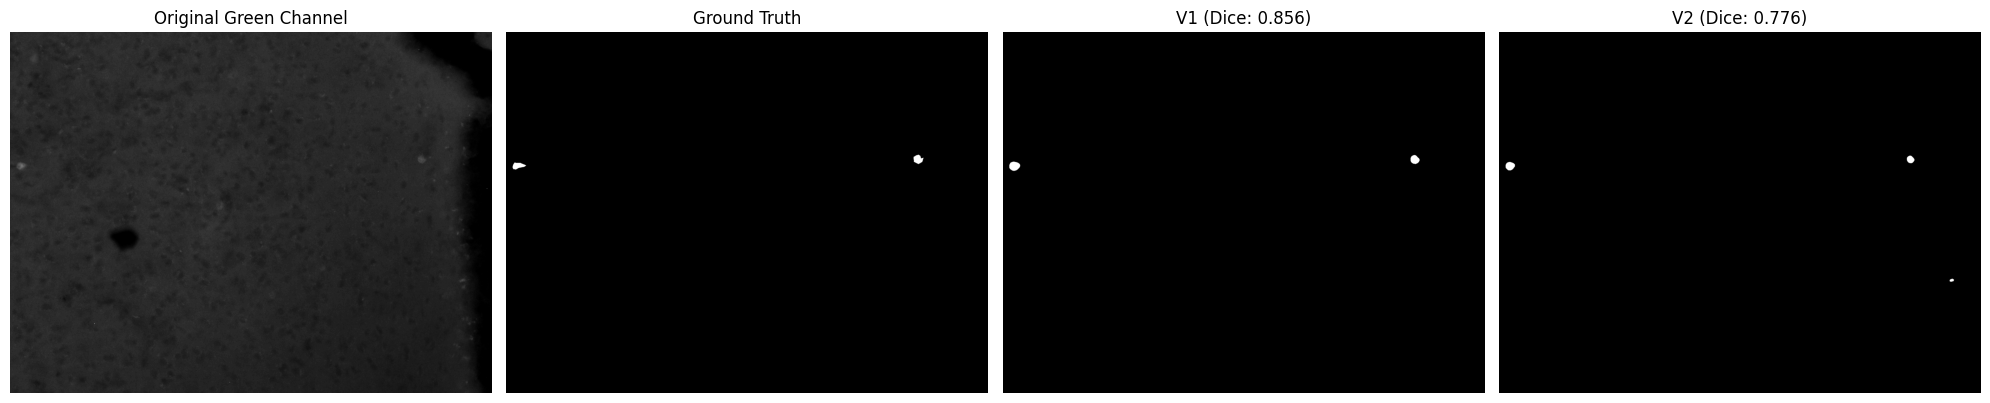

In [70]:
import matplotlib.pyplot as plt
import numpy as np

# Image filename
filename = "168.png"

# Load original fluorescence image
img = Image.open(
    os.path.join(TRAIN_IMAGES, filename)
).convert("RGB")

img_array = np.array(img)

# Extract green channel
green = img_array[:, :, 1]

# Load ground-truth mask
gt = np.array(
    Image.open(
        os.path.join(TRAIN_MASKS, filename)
    ).convert("L")
) > 0

# Retrieve the raw probability maps we already calculated
v1 = v1_prob_maps[filename]
v2 = v2_prob_maps[filename]

# Threshold probability maps at 0.5
v1_mask = (v1 > 0.5).astype(np.uint8)
v2_mask = (v2 > 0.5).astype(np.uint8)


def dice(pred, gt):
    """Calculate Dice overlap between two binary masks."""
    
    intersection = (pred * gt).sum()
    
    return (
        2 * intersection /
        (pred.sum() + gt.sum() + 1e-8)
    )


# Calculate Dice scores
v1_dice = dice(v1_mask, gt)
v2_dice = dice(v2_mask, gt)

print(f"V1 Dice: {v1_dice:.3f}")
print(f"V2 Dice: {v2_dice:.3f}")


# Visual comparison
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].imshow(green, cmap="gray")
axes[0].set_title("Original Green Channel")

axes[1].imshow(gt, cmap="gray")
axes[1].set_title("Ground Truth")

axes[2].imshow(v1_mask, cmap="gray")
axes[2].set_title(f"V1 (Dice: {v1_dice:.3f})")

axes[3].imshow(v2_mask, cmap="gray")
axes[3].set_title(f"V2 (Dice: {v2_dice:.3f})")

for ax in axes:
    ax.axis("off")

plt.tight_layout()

plt.savefig(
    "v1_vs_v2_168.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [71]:
def compute_dice(prob_map, mask_array, threshold):
    """Convert probability map to binary prediction and compute Dice."""
    binary = (prob_map > threshold).astype(np.uint8)
    gt = (mask_array > 0).astype(np.uint8)
    tp = np.sum((binary == 1) & (gt == 1))
    fp = np.sum((binary == 1) & (gt == 0))
    fn = np.sum((binary == 0) & (gt == 1))
    return (2 * tp) / (2 * tp + fp + fn) if (2 * tp + fp + fn) > 0 else 0


# Test ensemble weights and thresholds
weights = [1.0, 0.75, 0.5, 0.25, 0.0]  # V1 weight (V2 weight = 1 - this)
thresholds = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]

results = {}

for v1_weight in weights:
    v2_weight = 1.0 - v1_weight
    label = f"V1={v1_weight:.2f} V2={v2_weight:.2f}"
    results[label] = {}
    
    for threshold in thresholds:
        dice_scores = []
        
        for filename in val_files:
            # Blend probability maps
            ensemble_prob = v1_weight * v1_prob_maps[filename] + v2_weight * v2_prob_maps[filename]
            
            # Load ground truth
            mask = Image.open(os.path.join(TRAIN_MASKS, filename)).convert("L")
            mask_array = np.array(mask)
            
            dice = compute_dice(ensemble_prob, mask_array, threshold)
            dice_scores.append(dice)
        
        results[label][threshold] = np.mean(dice_scores)

# Print results table
print(f"{'':25}", end="")
for t in thresholds:
    print(f"  t={t:.2f}", end="")
print()

best_mean = 0
best_config = None

for label, threshold_results in results.items():
    print(f"{label:25}", end="")
    for t in thresholds:
        score = threshold_results[t]
        print(f"  {score:.3f}", end="")
        if score > best_mean:
            best_mean = score
            best_config = (label, t)
    print()

print(f"\nBest configuration: {best_config[0]} at threshold {best_config[1]}")
print(f"Best mean Dice: {best_mean:.3f}")
print(f"V1 baseline at 0.50: {results['V1=1.00 V2=0.00'][0.50]:.3f}")
print(f"V2 baseline at 0.50: {results['V1=0.00 V2=1.00'][0.50]:.3f}")

                           t=0.30  t=0.35  t=0.40  t=0.45  t=0.50  t=0.55  t=0.60
V1=1.00 V2=0.00            0.607  0.609  0.610  0.611  0.612  0.612  0.614
V1=0.75 V2=0.25            0.610  0.611  0.612  0.613  0.614  0.616  0.617
V1=0.50 V2=0.50            0.610  0.612  0.614  0.617  0.634  0.635  0.634
V1=0.25 V2=0.75            0.628  0.628  0.627  0.626  0.626  0.625  0.624
V1=0.00 V2=1.00            0.624  0.623  0.623  0.623  0.622  0.622  0.621

Best configuration: V1=0.50 V2=0.50 at threshold 0.55
Best mean Dice: 0.635
V1 baseline at 0.50: 0.612
V2 baseline at 0.50: 0.622


In [72]:
# Fine-grained threshold sweep for 50/50 ensemble
thresholds_fine = [round(t, 2) for t in np.arange(0.50, 0.61, 0.01)]

fine_results = {}

for threshold in thresholds_fine:
    dice_scores = []
    
    for filename in val_files:
        ensemble_prob = 0.5 * v1_prob_maps[filename] + 0.5 * v2_prob_maps[filename]
        
        mask = Image.open(os.path.join(TRAIN_MASKS, filename)).convert("L")
        mask_array = np.array(mask)
        
        dice = compute_dice(ensemble_prob, mask_array, threshold)
        dice_scores.append(dice)
    
    fine_results[threshold] = np.mean(dice_scores)
    print(f"Threshold {threshold:.2f}: {np.mean(dice_scores):.4f}")

best_threshold = max(fine_results, key=fine_results.get)
print(f"\nBest threshold: {best_threshold:.2f}")
print(f"Best mean Dice: {fine_results[best_threshold]:.4f}")

Threshold 0.50: 0.6338
Threshold 0.51: 0.6357
Threshold 0.52: 0.6359
Threshold 0.53: 0.6356
Threshold 0.54: 0.6354
Threshold 0.55: 0.6351
Threshold 0.56: 0.6348
Threshold 0.57: 0.6343
Threshold 0.58: 0.6340
Threshold 0.59: 0.6337
Threshold 0.60: 0.6337

Best threshold: 0.52
Best mean Dice: 0.6359


In [73]:
for collection in ["red", "yellow"]:
    collection_path = os.path.join(
        "/Users/ariellemondesir/Desktop/neurotech projects/project-01-Neuronal Segmentation/data/dataset_v2",
        collection
    )
    
    if os.path.exists(collection_path):
        trainval_images = os.path.join(collection_path, "trainval", "images")
        trainval_masks = os.path.join(collection_path, "trainval", "ground_truths", "masks")
        test_images = os.path.join(collection_path, "test", "images")
        
        if os.path.exists(trainval_images):
            imgs = os.listdir(trainval_images)
            masks = os.listdir(trainval_masks)
            test_imgs = os.listdir(test_images)
            
            sample = Image.open(os.path.join(trainval_images, sorted(imgs)[0]))
            
            print(f"{collection.upper()}")
            print(f"  Trainval images: {len(imgs)}")
            print(f"  Trainval masks:  {len(masks)}")
            print(f"  Test images:     {len(test_imgs)}")
            print(f"  Image size:      {sample.size}")
            print()
    else:
        print(f"{collection.upper()} — not downloaded yet")

RED
  Trainval images: 138
  Trainval masks:  138
  Test images:     46
  Image size:      (1600, 1200)

YELLOW
  Trainval images: 213
  Trainval masks:  213
  Test images:     70
  Image size:      (1600, 1200)



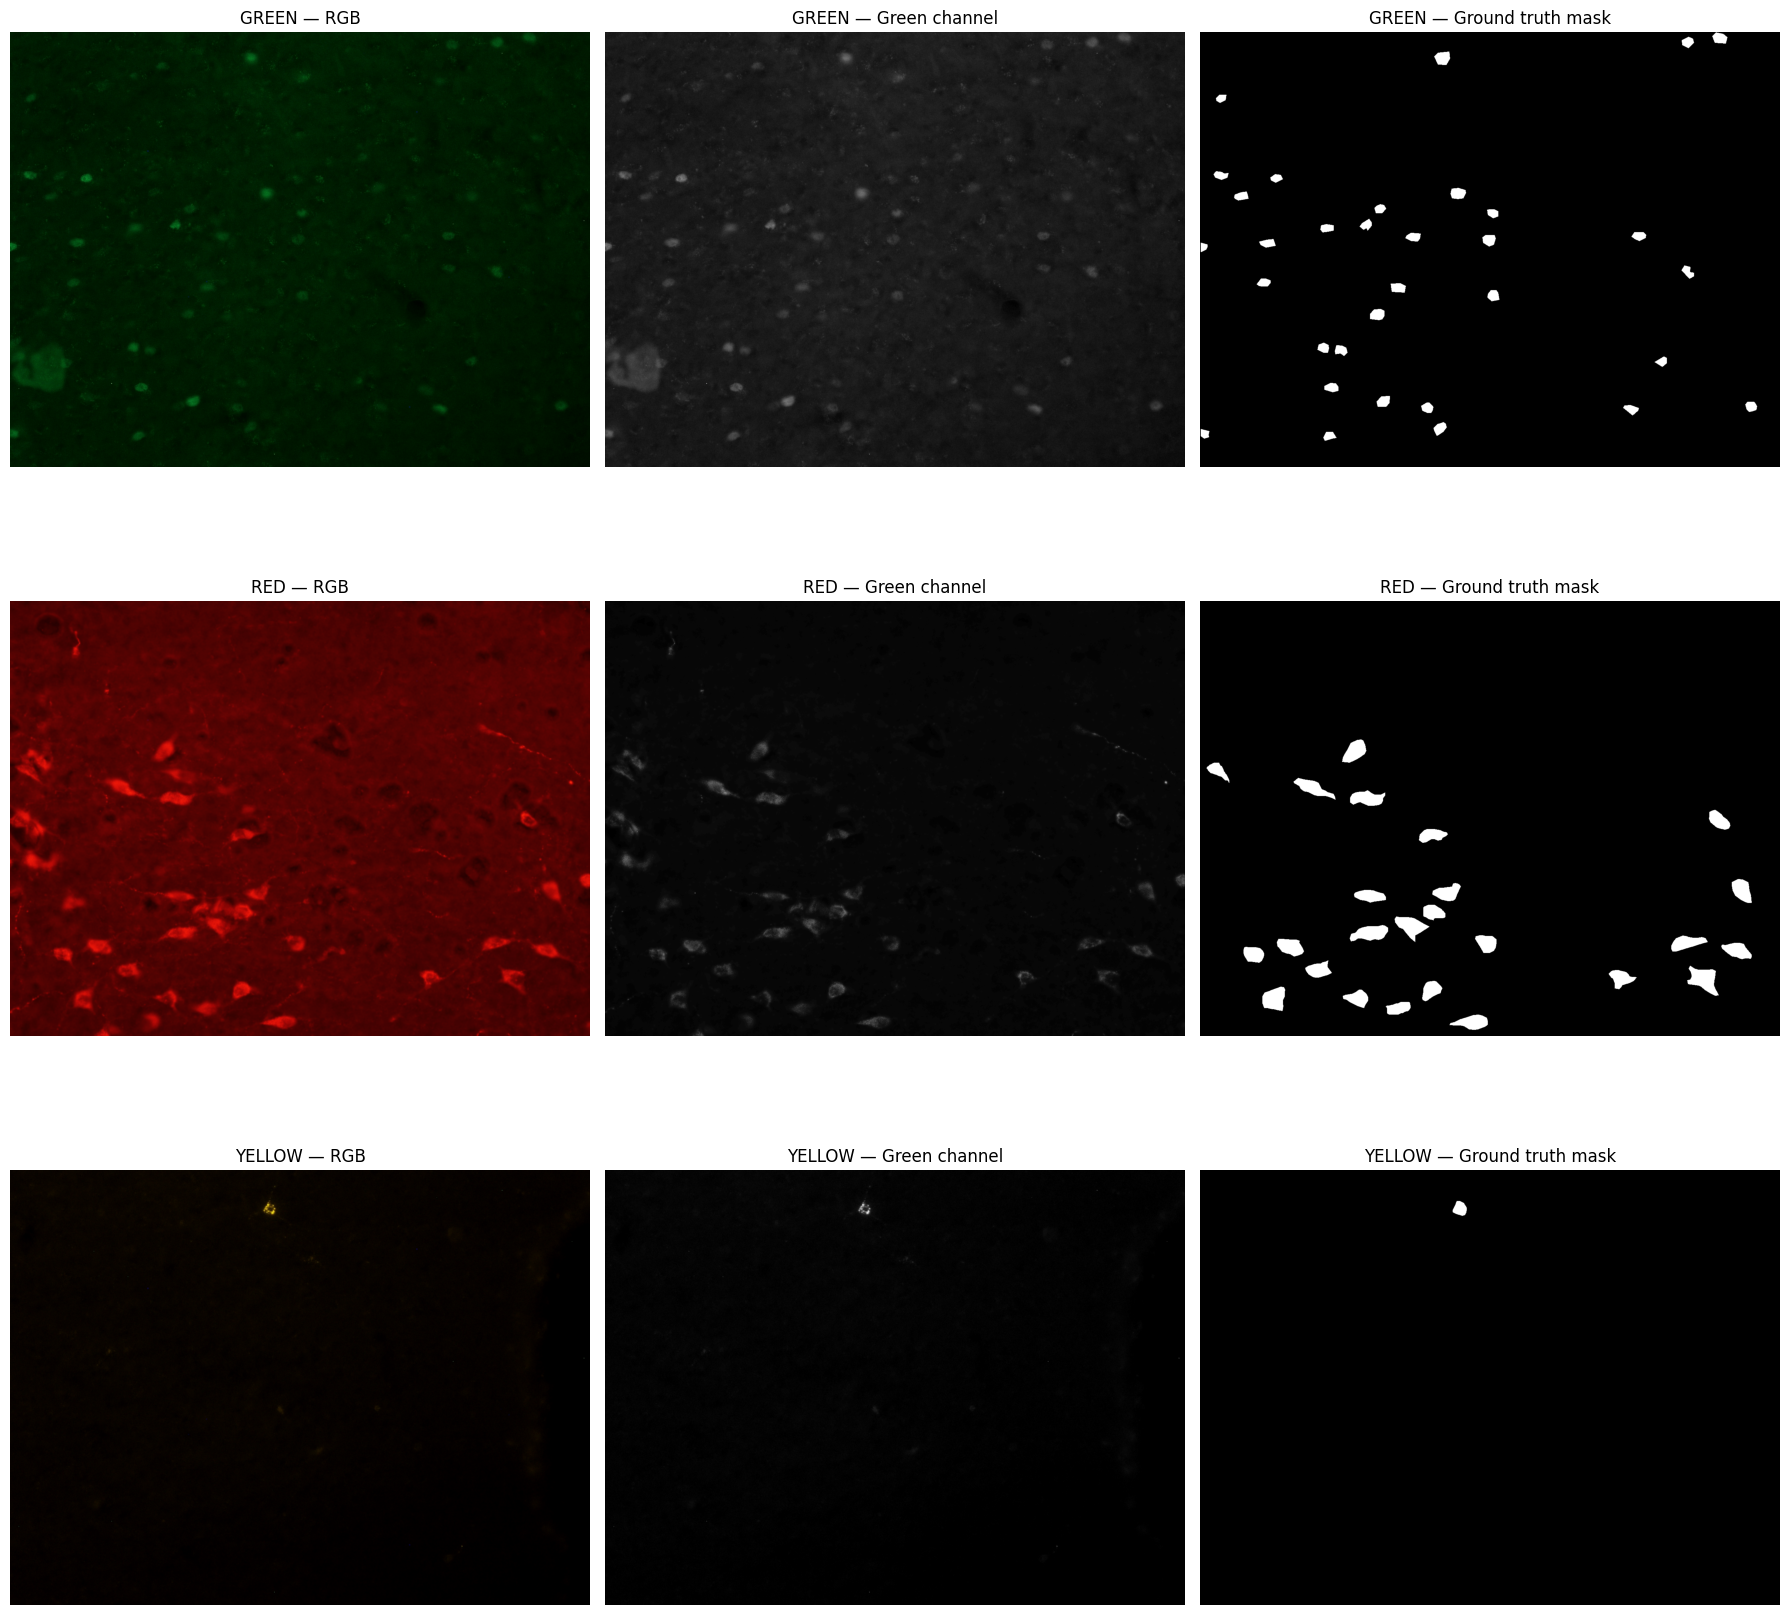

In [74]:
# Visualise one image and mask from each collection
collections = {
    "green": TRAIN_IMAGES,
    "red": "/Users/ariellemondesir/Desktop/neurotech projects/project-01-Neuronal Segmentation/data/dataset_v2/red/trainval/images",
    "yellow": "/Users/ariellemondesir/Desktop/neurotech projects/project-01-Neuronal Segmentation/data/dataset_v2/yellow/trainval/images"
}

collection_masks = {
    "green": TRAIN_MASKS,
    "red": "/Users/ariellemondesir/Desktop/neurotech projects/project-01-Neuronal Segmentation/data/dataset_v2/red/trainval/ground_truths/masks",
    "yellow": "/Users/ariellemondesir/Desktop/neurotech projects/project-01-Neuronal Segmentation/data/dataset_v2/yellow/trainval/ground_truths/masks"
}

fig, axes = plt.subplots(3, 3, figsize=(18, 18))

for i, (name, img_path) in enumerate(collections.items()):
    filename = sorted(os.listdir(img_path))[0]
    
    img = Image.open(os.path.join(img_path, filename)).convert("RGB")
    img_array = np.array(img)
    
    mask = Image.open(os.path.join(collection_masks[name], filename)).convert("L")
    mask_array = np.array(mask)
    
    # Show RGB image
    axes[i, 0].imshow(img_array)
    axes[i, 0].set_title(f"{name.upper()} — RGB")
    axes[i, 0].axis("off")
    
    # Show green channel
    axes[i, 1].imshow(img_array[:, :, 1], cmap="gray")
    axes[i, 1].set_title(f"{name.upper()} — Green channel")
    axes[i, 1].axis("off")
    
    # Show mask
    axes[i, 2].imshow(mask_array, cmap="gray")
    axes[i, 2].set_title(f"{name.upper()} — Ground truth mask")
    axes[i, 2].axis("off")

plt.tight_layout()
plt.show()

In [75]:
# Define paths for all three collections
collections = {
    "green": {
        "images": TRAIN_IMAGES,
        "masks": TRAIN_MASKS
    },
    "red": {
        "images": "/Users/ariellemondesir/Desktop/neurotech projects/project-01-Neuronal Segmentation/data/dataset_v2/red/trainval/images",
        "masks": "/Users/ariellemondesir/Desktop/neurotech projects/project-01-Neuronal Segmentation/data/dataset_v2/red/trainval/ground_truths/masks"
    },
    "yellow": {
        "images": "/Users/ariellemondesir/Desktop/neurotech projects/project-01-Neuronal Segmentation/data/dataset_v2/yellow/trainval/images",
        "masks": "/Users/ariellemondesir/Desktop/neurotech projects/project-01-Neuronal Segmentation/data/dataset_v2/yellow/trainval/ground_truths/masks"
    }
}

# --- PART 1: Basic image and mask statistics ---
for name, paths in collections.items():

    # Get filenames that exist in both images and masks folders
    image_files = sorted([
        f for f in os.listdir(paths["images"])
        if f in os.listdir(paths["masks"])
    ])

    # Use first image as representative example
    filename = image_files[0]

    # Load image and mask
    img = Image.open(os.path.join(paths["images"], filename)).convert("RGB")
    img_array = np.array(img)
    mask = Image.open(os.path.join(paths["masks"], filename)).convert("L")
    mask_array = np.array(mask)

    # Split into RGB channels
    r = img_array[:, :, 0]
    g = img_array[:, :, 1]
    b = img_array[:, :, 2]

    # Calculate what fraction of pixels are labelled as neurons
    neuron_fraction = np.mean(mask_array > 0)

    print("=" * 70)
    print(f"{name.upper()} COLLECTION")
    print("=" * 70)
    print(f"Example file:       {filename}")
    print(f"Image shape:        {img_array.shape}")
    print(f"Image dtype:        {img_array.dtype}")

    print(f"\n{'Channel':<10} {'Mean':>10} {'Min':>10} {'Max':>10}")
    print(f"{'Red':<10} {r.mean():>10.2f} {r.min():>10} {r.max():>10}")
    print(f"{'Green':<10} {g.mean():>10.2f} {g.min():>10} {g.max():>10}")
    print(f"{'Blue':<10} {b.mean():>10.2f} {b.min():>10} {b.max():>10}")

    print(f"\nMask values:        {np.unique(mask_array)}")
    print(f"Neuron pixels:      {np.sum(mask_array > 0):,}")
    print(f"Total pixels:       {mask_array.size:,}")
    print(f"Neuron percentage:  {neuron_fraction * 100:.2f}%")
    print()


# --- PART 2: Signal vs background by channel ---
# This tells us which channel actually carries the neuronal signal
for name, paths in collections.items():

    image_files = sorted([
        f for f in os.listdir(paths["images"])
        if f in os.listdir(paths["masks"])
    ])

    filename = image_files[0]

    img_array = np.array(Image.open(os.path.join(paths["images"], filename)).convert("RGB"))
    mask_array = np.array(Image.open(os.path.join(paths["masks"], filename)).convert("L"))

    # Create boolean masks for neuron and background pixels
    neuron = mask_array > 0
    background = mask_array == 0

    print("=" * 70)
    print(f"{name.upper()} — SIGNAL VS BACKGROUND")
    print("=" * 70)

    for channel_name, channel in [("Red", img_array[:,:,0]), ("Green", img_array[:,:,1]), ("Blue", img_array[:,:,2])]:
        neuron_mean = channel[neuron].mean()
        background_mean = channel[background].mean()
        difference = neuron_mean - background_mean
        print(f"{channel_name:<8} Neuron: {neuron_mean:>8.2f} | Background: {background_mean:>8.2f} | Difference: {difference:>8.2f}")

    print()

GREEN COLLECTION
Example file:       102.png
Image shape:        (1200, 1600, 3)
Image dtype:        uint8

Channel          Mean        Min        Max
Red              0.47          0        196
Green           27.27          1        254
Blue             1.47          0        197

Mask values:        [  0 255]
Neuron pixels:      24,369
Total pixels:       1,920,000
Neuron percentage:  1.27%

RED COLLECTION
Example file:       1911.png
Image shape:        (1200, 1600, 3)
Image dtype:        uint8

Channel          Mean        Min        Max
Red             83.66         29        245
Green            3.18          1         66
Blue             2.34          0         56

Mask values:        [  0 255]
Neuron pixels:      61,687
Total pixels:       1,920,000
Neuron percentage:  3.21%

YELLOW COLLECTION
Example file:       1000.png
Image shape:        (1200, 1600, 3)
Image dtype:        uint8

Channel          Mean        Min        Max
Red              6.60          0        251
Green

In [76]:
# Verify channel dominance across more images per collection
print("Verifying channel dominance across 20 images per collection...\n")

for name, paths in collections.items():
    image_files = sorted([
        f for f in os.listdir(paths["images"])
        if f in os.listdir(paths["masks"])
    ])
    
    # Sample 20 images
    sample_files = image_files[:20]
    
    r_diffs, g_diffs, b_diffs = [], [], []
    
    for filename in sample_files:
        img_array = np.array(Image.open(os.path.join(paths["images"], filename)).convert("RGB"))
        mask_array = np.array(Image.open(os.path.join(paths["masks"], filename)).convert("L"))
        
        neuron = mask_array > 0
        background = mask_array == 0
        
        # Skip images with no neurons
        if neuron.sum() == 0:
            continue
        
        for diffs, channel in [(r_diffs, img_array[:,:,0]), (g_diffs, img_array[:,:,1]), (b_diffs, img_array[:,:,2])]:
            diffs.append(channel[neuron].mean() - channel[background].mean())
    
    print(f"{name.upper()} — mean signal difference across {len(r_diffs)} images:")
    print(f"  Red channel:   {np.mean(r_diffs):>8.2f}")
    print(f"  Green channel: {np.mean(g_diffs):>8.2f}")
    print(f"  Blue channel:  {np.mean(b_diffs):>8.2f}")
    print(f"  Dominant:      {'Red' if np.mean(r_diffs) > np.mean(g_diffs) else 'Green'}")
    print()

Verifying channel dominance across 20 images per collection...

GREEN — mean signal difference across 20 images:
  Red channel:       2.05
  Green channel:    30.17
  Blue channel:     10.04
  Dominant:      Green

RED — mean signal difference across 20 images:
  Red channel:      99.45
  Green channel:     6.80
  Blue channel:      3.34
  Dominant:      Red

YELLOW — mean signal difference across 19 images:
  Red channel:      58.19
  Green channel:    45.68
  Blue channel:      5.07
  Dominant:      Red



In [77]:
# V4 — paths for all three collections

RED_TRAIN_IMAGES = "/Users/ariellemondesir/Desktop/neurotech projects/project-01-Neuronal Segmentation/data/dataset_v2/red/trainval/images"
RED_TRAIN_MASKS = "/Users/ariellemondesir/Desktop/neurotech projects/project-01-Neuronal Segmentation/data/dataset_v2/red/trainval/ground_truths/masks"

YELLOW_TRAIN_IMAGES = "/Users/ariellemondesir/Desktop/neurotech projects/project-01-Neuronal Segmentation/data/dataset_v2/yellow/trainval/images"
YELLOW_TRAIN_MASKS = "/Users/ariellemondesir/Desktop/neurotech projects/project-01-Neuronal Segmentation/data/dataset_v2/yellow/trainval/ground_truths/masks"


def get_files(images_path, masks_path):
    """Get filenames that have both an image and matching mask."""
    
    image_files = set(os.listdir(images_path))
    mask_files = set(os.listdir(masks_path))
    
    return sorted(image_files.intersection(mask_files))


def split_files(files, val_fraction=0.15, seed=42):
    """Split files into independent training and validation sets."""
    
    files = files.copy()
    
    # Use a local random generator so we do not alter
    # the random state used elsewhere in the notebook.
    rng = random.Random(seed)
    rng.shuffle(files)
    
    split = int((1 - val_fraction) * len(files))
    
    return files[:split], files[split:]


# Green (already split)
green_train = train_files
green_val = val_files

# Red
red_files = get_files(
    RED_TRAIN_IMAGES,
    RED_TRAIN_MASKS
)

red_train, red_val = split_files(red_files)

# Yellow
yellow_files = get_files(
    YELLOW_TRAIN_IMAGES,
    YELLOW_TRAIN_MASKS
)

yellow_train, yellow_val = split_files(yellow_files)


# ------------------------------------------------------------
# CHECK THE SPLITS
# ------------------------------------------------------------

print(f"Green  — train: {len(green_train)}, val: {len(green_val)}")
print(f"Red    — train: {len(red_train)}, val: {len(red_val)}")
print(f"Yellow — train: {len(yellow_train)}, val: {len(yellow_val)}")

print()

print(f"Total train: {len(green_train) + len(red_train) + len(yellow_train)}")
print(f"Total val:   {len(green_val) + len(red_val) + len(yellow_val)}")

Green  — train: 180, val: 32
Red    — train: 117, val: 21
Yellow — train: 181, val: 32

Total train: 478
Total val:   85


In [78]:
def extract_fluorescence_channel(img_array, collection):
    """Extract the relevant fluorescence channel based on collection type."""
    if collection == "green":
        return img_array[:, :, 1]  # Green channel
    elif collection == "red":
        return img_array[:, :, 0]  # Red channel
    elif collection == "yellow":
        # Both R and G carry signal — average them
        r = img_array[:, :, 0].astype(np.float32)
        g = img_array[:, :, 1].astype(np.float32)
        return ((r + g) / 2).astype(np.uint8)


# Build combined patch index for all three collections
collection_train_data = [
    ("green", green_train, TRAIN_IMAGES, TRAIN_MASKS),
    ("red", red_train, RED_TRAIN_IMAGES, RED_TRAIN_MASKS),
    ("yellow", yellow_train, YELLOW_TRAIN_IMAGES, YELLOW_TRAIN_MASKS),
]

v4_patch_index = []

for collection, files, images_path, masks_path in collection_train_data:
    print(f"Building patch index for {collection}...")
    
    for filename in files:
        mask = Image.open(os.path.join(masks_path, filename)).convert("L")
        mask_array = np.array(mask)
        mask_padded = pad_to_patch_size(mask_array)
        
        n_rows = mask_padded.shape[0] // PATCH_SIZE
        n_cols = mask_padded.shape[1] // PATCH_SIZE
        
        for row in range(n_rows):
            for col in range(n_cols):
                r_start = row * PATCH_SIZE
                c_start = col * PATCH_SIZE
                patch = mask_padded[r_start:r_start+PATCH_SIZE, c_start:c_start+PATCH_SIZE]
                
                neuron_fraction = patch.mean() / 255
                
                if neuron_fraction == 0:
                    category = "background"
                elif neuron_fraction <= 0.05:
                    category = "sparse"
                else:
                    category = "substantial"
                
                v4_patch_index.append({
                    "filename": filename,
                    "collection": collection,
                    "images_path": images_path,
                    "masks_path": masks_path,
                    "row": row,
                    "col": col,
                    "neuron_fraction": neuron_fraction,
                    "category": category
                })

v4_patch_df = pd.DataFrame(v4_patch_index)

print(f"\nTotal patches: {len(v4_patch_df)}")
print(v4_patch_df.groupby(["collection", "category"]).size().unstack(fill_value=0))

Building patch index for green...
Building patch index for red...
Building patch index for yellow...

Total patches: 18858
category    background  sparse  substantial
collection                                 
green             4249    1983           68
red               4095     974         1154
yellow            5180    1011          144


In [79]:
# Build balanced V4 training patch index
# Strategy: keep all neuron-containing patches per collection,
# sample equal background patches per collection

v4_train_patches = []

for collection in ["green", "red", "yellow"]:
    collection_patches = v4_patch_df[v4_patch_df["collection"] == collection]
    
    # Split by category
    substantial = collection_patches[collection_patches["category"] == "substantial"].to_dict("records")
    sparse = collection_patches[collection_patches["category"] == "sparse"].to_dict("records")
    background = collection_patches[collection_patches["category"] == "background"].to_dict("records")
    
    # Keep all neuron-containing patches
    neuron_patches = substantial + sparse
    
    # Sample equal number of background patches
    n_background = len(neuron_patches)
    rng = random.Random(42)
    background_sampled = rng.sample(background, min(n_background, len(background)))
    
    collection_total = neuron_patches + background_sampled
    
    print(f"{collection.upper()}")
    print(f"  Substantial: {len(substantial)}")
    print(f"  Sparse:      {len(sparse)}")
    print(f"  Background:  {len(background_sampled)}")
    print(f"  Total:       {len(collection_total)}")
    print()
    
    v4_train_patches.extend(collection_total)

# Shuffle combined patch list
random.Random(42).shuffle(v4_train_patches)

print(f"Total V4 training patches: {len(v4_train_patches)}")

GREEN
  Substantial: 68
  Sparse:      1983
  Background:  2051
  Total:       4102

RED
  Substantial: 1154
  Sparse:      974
  Background:  2128
  Total:       4256

YELLOW
  Substantial: 144
  Sparse:      1011
  Background:  1155
  Total:       2310

Total V4 training patches: 10668


In [80]:
class V4PatchDataset(Dataset):
    """Dataset for V4 — handles green, red and yellow collections
    by extracting the appropriate fluorescence channel for each."""
    
    def __init__(self, patch_index, patch_size=256, augment=True):
        self.patch_size = patch_size
        self.augment = augment
        self.image_patches = []
        self.mask_patches = []
        
        print("Preloading V4 patches into memory...")
        
        for patch_info in patch_index:
            filename = patch_info["filename"]
            collection = patch_info["collection"]
            images_path = patch_info["images_path"]
            masks_path = patch_info["masks_path"]
            row = patch_info["row"]
            col = patch_info["col"]
            
            # Load image and extract correct fluorescence channel
            img = Image.open(os.path.join(images_path, filename)).convert("RGB")
            img_array = np.array(img)
            signal = extract_fluorescence_channel(img_array, collection)
            signal_padded = pad_to_patch_size(signal, patch_size)
            
            # Load mask
            mask = Image.open(os.path.join(masks_path, filename)).convert("L")
            mask_array = np.array(mask)
            mask_padded = pad_to_patch_size(mask_array, patch_size)
            
            # Extract patch
            r_start = row * patch_size
            c_start = col * patch_size
            img_patch = signal_padded[r_start:r_start+patch_size, c_start:c_start+patch_size]
            mask_patch = mask_padded[r_start:r_start+patch_size, c_start:c_start+patch_size]
            
            self.image_patches.append(img_patch)
            self.mask_patches.append(mask_patch)
        
        print(f"Preloaded {len(self.image_patches)} patches")

    def __len__(self):
        return len(self.image_patches)

    def __getitem__(self, idx):
        img_patch = self.image_patches[idx].copy()
        mask_patch = self.mask_patches[idx].copy()
        
        if self.augment:
            # Horizontal flip
            if random.random() > 0.5:
                img_patch = np.fliplr(img_patch)
                mask_patch = np.fliplr(mask_patch)
            
            # Vertical flip
            if random.random() > 0.5:
                img_patch = np.flipud(img_patch)
                mask_patch = np.flipud(mask_patch)
            
            # 90 degree rotation
            k = random.randint(0, 3)
            img_patch = np.rot90(img_patch, k)
            mask_patch = np.rot90(mask_patch, k)
            
            # Brightness variation
            brightness_factor = random.uniform(0.7, 1.3)
            img_patch = np.clip(img_patch * brightness_factor, 0, 255)
            
            # Gaussian noise
            noise = np.random.normal(0, 5, img_patch.shape)
            img_patch = np.clip(img_patch + noise, 0, 255)
        
        image_tensor = torch.tensor(img_patch.copy(), dtype=torch.float32) / 255.0
        mask_tensor = torch.tensor(mask_patch.copy() > 0, dtype=torch.float32)
        
        image_tensor = image_tensor.unsqueeze(0)
        mask_tensor = mask_tensor.unsqueeze(0)
        
        return image_tensor, mask_tensor


# Create V4 training dataset
train_v4 = V4PatchDataset(v4_train_patches, augment=True)
train_loader_v4 = DataLoader(train_v4, batch_size=8, shuffle=True)

print(f"Training batches: {len(train_loader_v4)}")

Preloading V4 patches into memory...


UnidentifiedImageError: cannot identify image file '/Users/ariellemondesir/Desktop/neurotech projects/project-01-Neuronal Segmentation/data/dataset_v2/green/trainval/ground_truths/masks/87.png'

In [81]:
import os

# Check for corrupted files across all three collections
collection_mask_paths = {
    "green": TRAIN_MASKS,
    "red": RED_TRAIN_MASKS,
    "yellow": YELLOW_TRAIN_MASKS
}

bad_files = []

for collection, masks_path in collection_mask_paths.items():
    for filename in os.listdir(masks_path):
        filepath = os.path.join(masks_path, filename)
        try:
            img = Image.open(filepath)
            img.verify()
        except Exception as e:
            bad_files.append((collection, filename, str(e)))
            print(f"Bad file: {collection}/{filename} — {e}")

print(f"\nTotal bad files found: {len(bad_files)}")


Total bad files found: 0


In [82]:
import struct

# Check the specific file
filepath = "/Users/ariellemondesir/Desktop/neurotech projects/project-01-Neuronal Segmentation/data/dataset_v2/green/trainval/ground_truths/masks/87.png"

# Check file size
size = os.path.getsize(filepath)
print(f"File size: {size} bytes")

# Read first few bytes to check the file signature
with open(filepath, "rb") as f:
    header = f.read(8)
    print(f"File header (hex): {header.hex()}")
    print(f"PNG signature: 89504e470d0a1a0a")
    print(f"Is PNG: {header.hex() == '89504e470d0a1a0a'}")

File size: 8583 bytes
File header (hex): 89504e470d0a1a0a
PNG signature: 89504e470d0a1a0a
Is PNG: True


In [83]:
# Check if 87.png exists in both images and masks
img_path = os.path.join(TRAIN_IMAGES, "87.png")
mask_path = os.path.join(TRAIN_MASKS, "87.png")

print(f"Image exists: {os.path.exists(img_path)}")
print(f"Mask exists: {os.path.exists(mask_path)}")

# Try opening both directly
try:
    img = Image.open(img_path)
    print(f"Image opens fine: {img.size}")
except Exception as e:
    print(f"Image error: {e}")

try:
    mask = Image.open(mask_path)
    print(f"Mask opens fine: {mask.size}")
except Exception as e:
    print(f"Mask error: {e}")

Image exists: True
Mask exists: True
Image opens fine: (1600, 1200)
Mask opens fine: (1600, 1200)


In [84]:
# Find the patch entry for 87.png in the green collection
problem_patches = [p for p in v4_train_patches if p["filename"] == "87.png"]

for p in problem_patches:
    print(p)
    
    # Try opening the mask with the exact path from the patch index
    full_path = os.path.join(p["masks_path"], p["filename"])
    print(f"Full path: {full_path}")
    print(f"Path exists: {os.path.exists(full_path)}")
    
    try:
        mask = Image.open(full_path).convert("L")
        print(f"Opens fine: {mask.size}")
    except Exception as e:
        print(f"Error: {e}")
    print()

{'filename': '87.png', 'collection': 'green', 'images_path': '/Users/ariellemondesir/Desktop/neurotech projects/project-01-Neuronal Segmentation/data/dataset_v2/green/trainval/images', 'masks_path': '/Users/ariellemondesir/Desktop/neurotech projects/project-01-Neuronal Segmentation/data/dataset_v2/green/trainval/ground_truths/masks', 'row': 4, 'col': 2, 'neuron_fraction': 0.02850341796875, 'category': 'sparse'}
Full path: /Users/ariellemondesir/Desktop/neurotech projects/project-01-Neuronal Segmentation/data/dataset_v2/green/trainval/ground_truths/masks/87.png
Path exists: True
Opens fine: (1600, 1200)

{'filename': '87.png', 'collection': 'green', 'images_path': '/Users/ariellemondesir/Desktop/neurotech projects/project-01-Neuronal Segmentation/data/dataset_v2/green/trainval/images', 'masks_path': '/Users/ariellemondesir/Desktop/neurotech projects/project-01-Neuronal Segmentation/data/dataset_v2/green/trainval/ground_truths/masks', 'row': 3, 'col': 3, 'neuron_fraction': 0.104660034179

In [85]:
class V4PatchDataset(Dataset):
    """Dataset for V4.
    
    Loads each source image once, extracts the appropriate fluorescence
    signal, and then creates only the patches selected in v4_train_patches.
    """

    def __init__(self, patch_index, patch_size=256, augment=True):
        self.patch_size = patch_size
        self.augment = augment
        self.image_patches = []
        self.mask_patches = []

        print("Preloading V4 patches into memory...")

        # Group patch entries by source image.
        # Each image can contribute up to 35 patches.
        patches_by_image = {}

        for patch_info in patch_index:
            key = (
                patch_info["collection"],
                patch_info["filename"]
            )

            if key not in patches_by_image:
                patches_by_image[key] = []

            patches_by_image[key].append(patch_info)

        print(f"Loading {len(patches_by_image)} unique source images...")

        # -------------------------------------------------------------
        # Process each unique image ONCE
        # -------------------------------------------------------------
        for (collection, filename), patches in patches_by_image.items():

            # Get paths from the first patch belonging to this image
            images_path = patches[0]["images_path"]
            masks_path = patches[0]["masks_path"]

            # Load image
            with Image.open(
                os.path.join(images_path, filename)
            ) as img:

                img_array = np.array(
                    img.convert("RGB")
                )

            # Extract collection-specific fluorescence signal
            signal = extract_fluorescence_channel(
                img_array,
                collection
            )

            # Pad image
            signal_padded = pad_to_patch_size(
                signal,
                patch_size
            )

            # Load mask
            with Image.open(
                os.path.join(masks_path, filename)
            ) as mask:

                mask_array = np.array(
                    mask.convert("L")
                )

            # Pad mask
            mask_padded = pad_to_patch_size(
                mask_array,
                patch_size
            )

            # ---------------------------------------------------------
            # Extract only the patches selected for training
            # ---------------------------------------------------------
            for patch_info in patches:

                row = patch_info["row"]
                col = patch_info["col"]

                r_start = row * patch_size
                c_start = col * patch_size

                img_patch = signal_padded[
                    r_start:r_start + patch_size,
                    c_start:c_start + patch_size
                ]

                mask_patch = mask_padded[
                    r_start:r_start + patch_size,
                    c_start:c_start + patch_size
                ]

                self.image_patches.append(img_patch)
                self.mask_patches.append(mask_patch)

        print(f"Preloaded {len(self.image_patches)} patches")

    def __len__(self):
        return len(self.image_patches)

    def __getitem__(self, idx):

        img_patch = self.image_patches[idx].copy()
        mask_patch = self.mask_patches[idx].copy()

        if self.augment:

            # Horizontal flip
            if random.random() > 0.5:
                img_patch = np.fliplr(img_patch)
                mask_patch = np.fliplr(mask_patch)

            # Vertical flip
            if random.random() > 0.5:
                img_patch = np.flipud(img_patch)
                mask_patch = np.flipud(mask_patch)

            # Random 90-degree rotation
            k = random.randint(0, 3)

            img_patch = np.rot90(img_patch, k)
            mask_patch = np.rot90(mask_patch, k)

            # Brightness variation
            brightness_factor = random.uniform(0.7, 1.3)

            img_patch = np.clip(
                img_patch * brightness_factor,
                0,
                255
            )

            # Gaussian noise
            noise = np.random.normal(
                0,
                5,
                img_patch.shape
            )

            img_patch = np.clip(
                img_patch + noise,
                0,
                255
            )

        # Convert image to tensor
        image_tensor = torch.tensor(
            img_patch.copy(),
            dtype=torch.float32
        ) / 255.0

        # Convert mask to binary tensor
        mask_tensor = torch.tensor(
            mask_patch.copy() > 0,
            dtype=torch.float32
        )

        # Add channel dimension
        image_tensor = image_tensor.unsqueeze(0)
        mask_tensor = mask_tensor.unsqueeze(0)

        return image_tensor, mask_tensor


# Create V4 training dataset
train_v4 = V4PatchDataset(
    v4_train_patches,
    augment=True
)

train_loader_v4 = DataLoader(
    train_v4,
    batch_size=8,
    shuffle=True
)

print(f"Training batches: {len(train_loader_v4)}")

Preloading V4 patches into memory...
Loading 478 unique source images...
Preloaded 10668 patches
Training batches: 1334


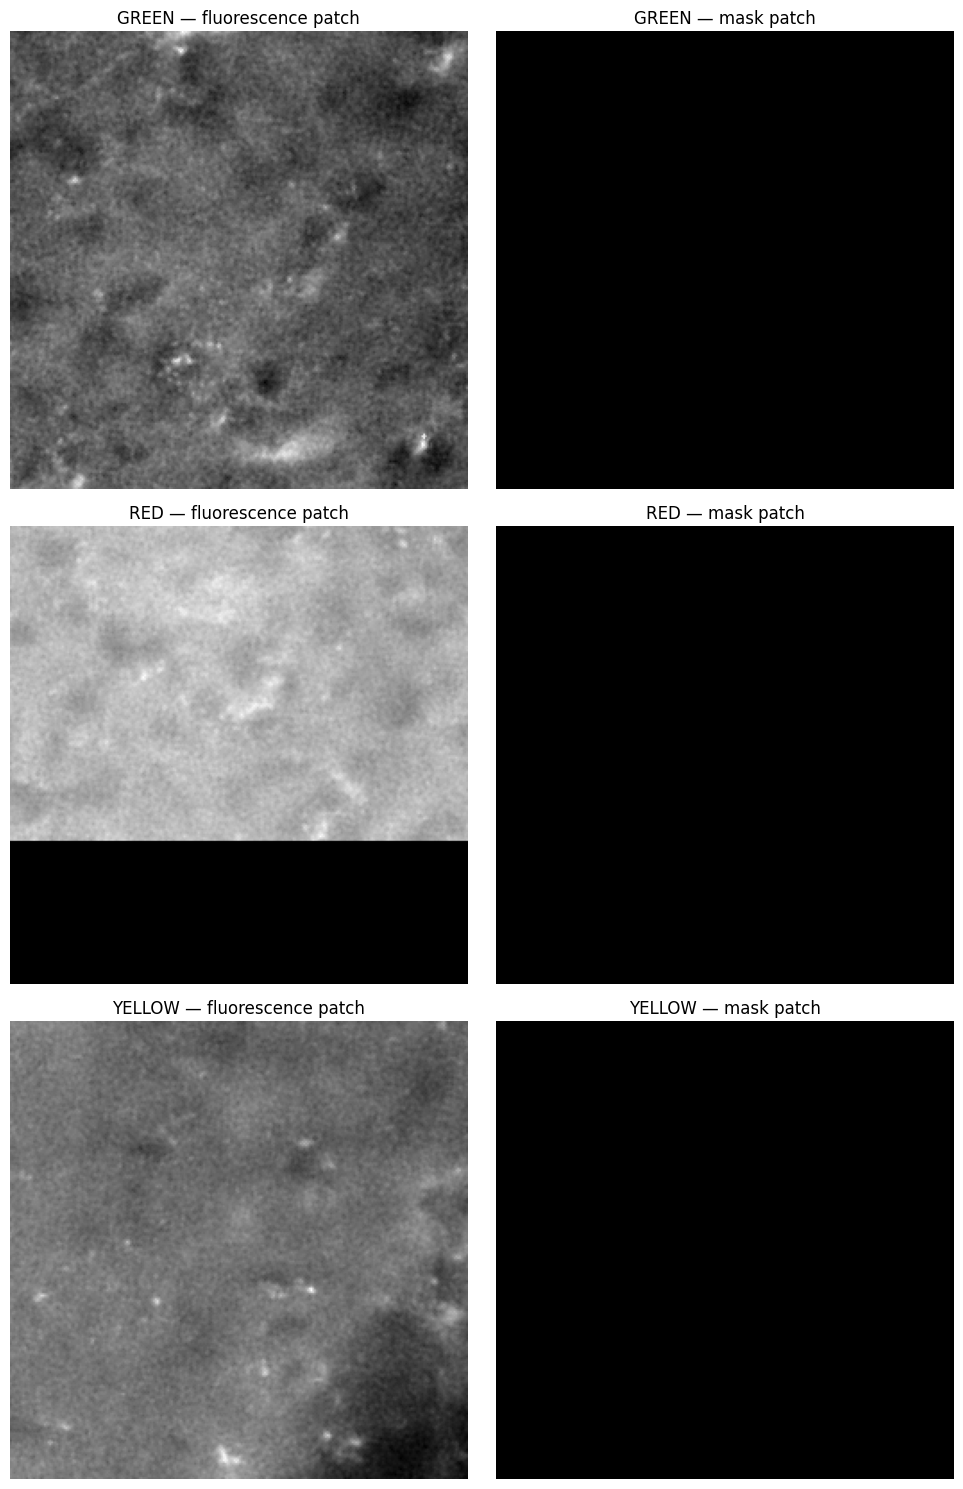

In [87]:
# Sanity check — visualise one patch from each collection
fig, axes = plt.subplots(3, 2, figsize=(10, 15))

collections_to_check = ["green", "red", "yellow"]

for i, collection in enumerate(collections_to_check):
    # Find first patch from this collection
    idx = next(j for j, p in enumerate(v4_train_patches) if p["collection"] == collection)
    
    img_patch = train_v4.image_patches[idx]
    mask_patch = train_v4.mask_patches[idx]
    
    axes[i, 0].imshow(img_patch, cmap="gray")
    axes[i, 0].set_title(f"{collection.upper()} — fluorescence patch")
    axes[i, 0].axis("off")
    
    axes[i, 1].imshow(mask_patch, cmap="gray")
    axes[i, 1].set_title(f"{collection.upper()} — mask patch")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

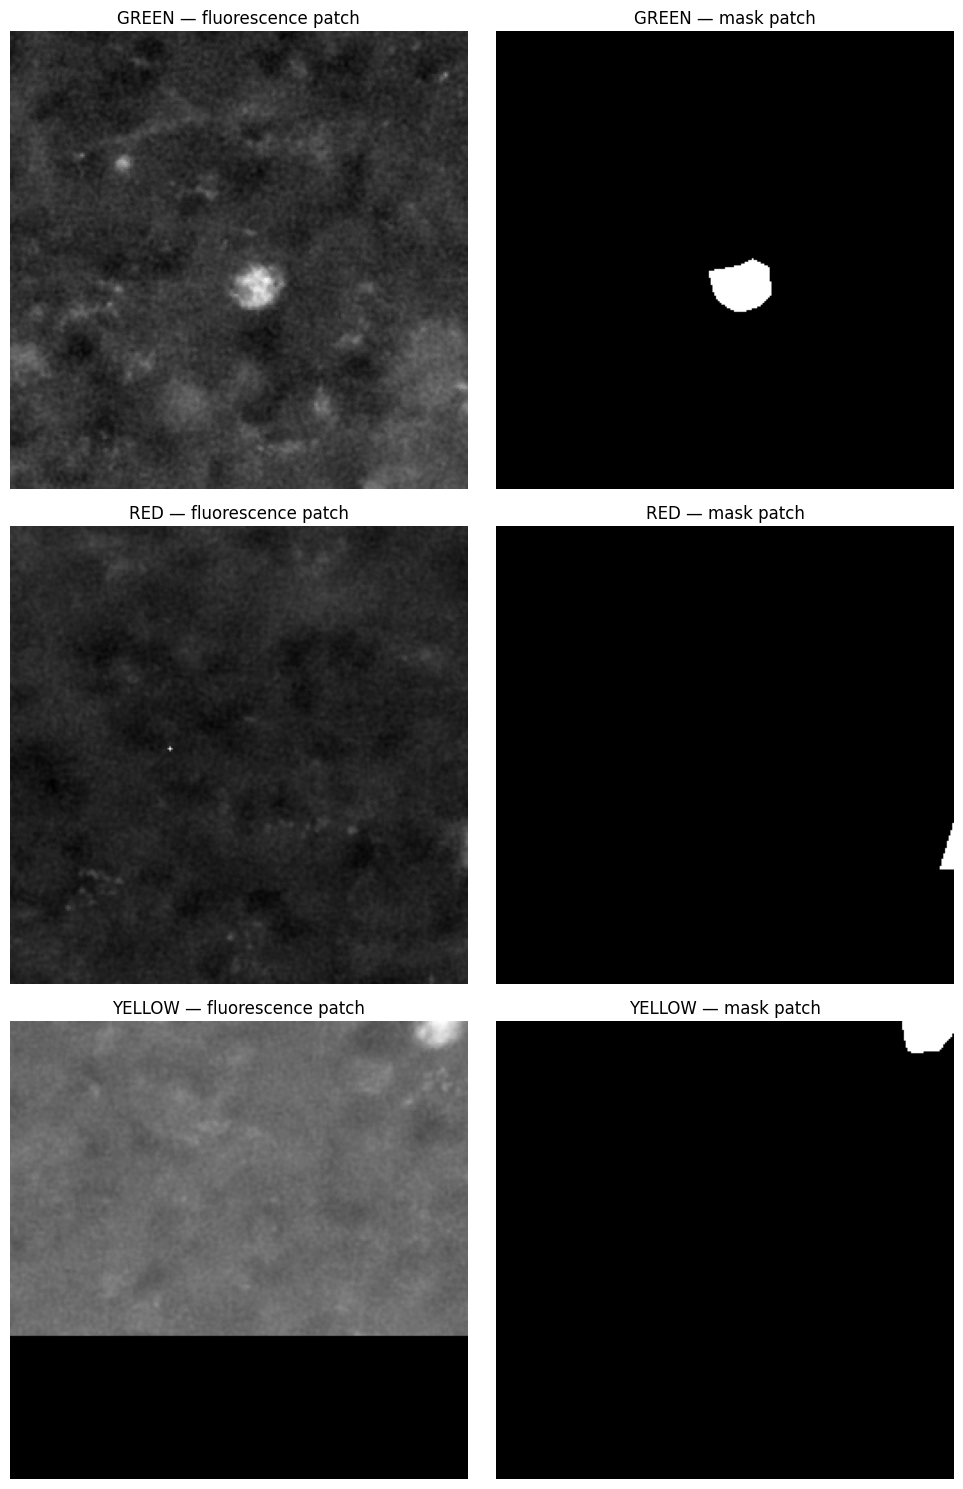

In [88]:
# Find patches with neurons for each collection
fig, axes = plt.subplots(3, 2, figsize=(10, 15))

for i, collection in enumerate(["green", "red", "yellow"]):
    # Find first patch from this collection that has neurons
    idx = next(
        j for j, p in enumerate(v4_train_patches)
        if p["collection"] == collection and p.get("neuron_fraction", 0) > 0.02
    )
    
    img_patch = train_v4.image_patches[idx]
    mask_patch = train_v4.mask_patches[idx]
    
    axes[i, 0].imshow(img_patch, cmap="gray")
    axes[i, 0].set_title(f"{collection.upper()} — fluorescence patch")
    axes[i, 0].axis("off")
    
    axes[i, 1].imshow(mask_patch, cmap="gray")
    axes[i, 1].set_title(f"{collection.upper()} — mask patch")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

In [90]:
# Train V4 — multi-collection model
model_v4 = UNet(in_channels=1, out_channels=1).to(device)
optimizer_v4 = optim.Adam(model_v4.parameters(), lr=1e-4)

NUM_EPOCHS = 10
train_losses_v4 = []
val_losses_v4 = []

for epoch in range(NUM_EPOCHS):
    train_loss = train_one_epoch(model_v4, train_loader_v4, optimizer_v4, device)
    
    # Validate on green only for now — same as V1/V2/V3
    val_loss = validate(model_v4, val_loader_v2, device)
    
    train_losses_v4.append(train_loss)
    val_losses_v4.append(val_loss)
    
    print(f"Epoch {epoch+1}/{NUM_EPOCHS} — Train loss: {train_loss:.4f} | Val loss: {val_loss:.4f}")

torch.save(model_v4.state_dict(), "unet_v4_multicollection.pth")
print("Model V4 saved")

Epoch 1/10 — Train loss: 0.7957 | Val loss: 0.9507
Epoch 2/10 — Train loss: 0.6745 | Val loss: 0.7780
Epoch 3/10 — Train loss: 0.5976 | Val loss: 0.6737
Epoch 4/10 — Train loss: 0.5358 | Val loss: 0.6821
Epoch 5/10 — Train loss: 0.4834 | Val loss: 0.5390
Epoch 6/10 — Train loss: 0.4558 | Val loss: 0.5758
Epoch 7/10 — Train loss: 0.4428 | Val loss: 0.5850
Epoch 8/10 — Train loss: 0.4272 | Val loss: 0.5323
Epoch 9/10 — Train loss: 0.4278 | Val loss: 0.5110
Epoch 10/10 — Train loss: 0.4237 | Val loss: 0.5474
Model V4 saved


In [91]:
# Load V4 model
model_v4 = UNet(in_channels=1, out_channels=1).to(device)
model_v4.load_state_dict(torch.load("unet_v4_multicollection.pth"))
model_v4.eval()

# Evaluation function for a full collection
def evaluate_collection(model, files, images_path, masks_path, collection, device, patch_size=256):
    dice_scores = []
    
    for filename in files:
        img = Image.open(os.path.join(images_path, filename)).convert("RGB")
        img_array = np.array(img)
        signal = extract_fluorescence_channel(img_array, collection)
        signal_padded = pad_to_patch_size(signal, patch_size)
        
        mask = Image.open(os.path.join(masks_path, filename)).convert("L")
        mask_array = np.array(mask)
        
        n_rows = signal_padded.shape[0] // patch_size
        n_cols = signal_padded.shape[1] // patch_size
        canvas = np.zeros_like(signal_padded, dtype=np.float32)
        
        with torch.no_grad():
            for row in range(n_rows):
                for col in range(n_cols):
                    r_start = row * patch_size
                    c_start = col * patch_size
                    patch = signal_padded[r_start:r_start+patch_size, c_start:c_start+patch_size]
                    tensor = torch.tensor(patch, dtype=torch.float32) / 255.0
                    tensor = tensor.unsqueeze(0).unsqueeze(0).to(device)
                    pred = model(tensor)
                    canvas[r_start:r_start+patch_size, c_start:c_start+patch_size] = pred.squeeze().cpu().numpy()
        
        prediction = (canvas[:mask_array.shape[0], :mask_array.shape[1]] > 0.5).astype(np.uint8)
        gt = (mask_array > 0).astype(np.uint8)
        
        tp = np.sum((prediction == 1) & (gt == 1))
        fp = np.sum((prediction == 1) & (gt == 0))
        fn = np.sum((prediction == 0) & (gt == 1))
        dice = (2 * tp) / (2 * tp + fp + fn) if (2 * tp + fp + fn) > 0 else 0
        dice_scores.append(dice)
    
    return np.array(dice_scores)


# Evaluate on all three validation sets
print("Evaluating green validation set...")
green_dice = evaluate_collection(model_v4, green_val, TRAIN_IMAGES, TRAIN_MASKS, "green", device)

print("Evaluating red validation set...")
red_dice = evaluate_collection(model_v4, red_val, RED_TRAIN_IMAGES, RED_TRAIN_MASKS, "red", device)

print("Evaluating yellow validation set...")
yellow_dice = evaluate_collection(model_v4, yellow_val, YELLOW_TRAIN_IMAGES, YELLOW_TRAIN_MASKS, "yellow", device)

# Print results
for name, scores in [("Green", green_dice), ("Red", red_dice), ("Yellow", yellow_dice)]:
    print(f"\n{name} validation ({len(scores)} images):")
    print(f"  Mean:   {scores.mean():.3f}")
    print(f"  Median: {np.median(scores):.3f}")
    print(f"  Std:    {scores.std():.3f}")
    print(f"  Best:   {scores.max():.3f}")
    print(f"  Worst:  {scores.min():.3f}")

print(f"\nV3 green baseline: 0.636")

Evaluating green validation set...
Evaluating red validation set...
Evaluating yellow validation set...

Green validation (32 images):
  Mean:   0.608
  Median: 0.646
  Std:    0.178
  Best:   0.859
  Worst:  0.000

Red validation (21 images):
  Mean:   0.572
  Median: 0.564
  Std:    0.128
  Best:   0.842
  Worst:  0.383

Yellow validation (32 images):
  Mean:   0.615
  Median: 0.716
  Std:    0.258
  Best:   0.948
  Worst:  0.000

V3 green baseline: 0.636


In [92]:
# Compute V4 probability maps for green validation images
print("Computing V4 probability maps...")

v4_prob_maps = {
    f: get_probability_map(model_v4, f, TRAIN_IMAGES, device)
    for f in green_val
}

print("Done.")

# Quick check
example = green_val[0]
print(f"V4 range: {v4_prob_maps[example].min():.3f} to {v4_prob_maps[example].max():.3f}")

Computing V4 probability maps...
Done.
V4 range: 0.000 to 0.983


In [93]:
# Threshold sweep for V4 alone
thresholds = [round(t, 2) for t in np.arange(0.30, 0.61, 0.05)]

v4_threshold_results = {}

for threshold in thresholds:
    dice_scores = []
    for filename in green_val:
        mask = Image.open(os.path.join(TRAIN_MASKS, filename)).convert("L")
        mask_array = np.array(mask)
        dice = compute_dice(v4_prob_maps[filename], mask_array, threshold)
        dice_scores.append(dice)
    v4_threshold_results[threshold] = np.mean(dice_scores)

print("V4 threshold sweep:")
for t, score in v4_threshold_results.items():
    print(f"  t={t:.2f}: {score:.4f}")

best_v4_threshold = max(v4_threshold_results, key=v4_threshold_results.get)
print(f"\nBest V4 threshold: {best_v4_threshold:.2f} → {v4_threshold_results[best_v4_threshold]:.4f}")

# Also test V4 in ensemble with V1 and V2
print("\nEnsemble sweep (V1 + V2 + V4):")
ensemble_configs = [
    ("V3 (V1+V2 50:50)", 0.5, 0.5, 0.0),
    ("V1+V4 50:50",      0.5, 0.0, 0.5),
    ("V2+V4 50:50",      0.0, 0.5, 0.5),
    ("V1+V2+V4 equal",   0.33, 0.33, 0.34),
]

for label, w1, w2, w4 in ensemble_configs:
    dice_scores = []
    for filename in green_val:
        ensemble = w1 * v1_prob_maps[filename] + w2 * v2_prob_maps[filename] + w4 * v4_prob_maps[filename]
        mask = Image.open(os.path.join(TRAIN_MASKS, filename)).convert("L")
        mask_array = np.array(mask)
        dice = compute_dice(ensemble, mask_array, 0.52)
        dice_scores.append(dice)
    print(f"  {label}: {np.mean(dice_scores):.4f}")

V4 threshold sweep:
  t=0.30: 0.6106
  t=0.35: 0.6099
  t=0.40: 0.6093
  t=0.45: 0.6087
  t=0.50: 0.6079
  t=0.55: 0.6072
  t=0.60: 0.6062

Best V4 threshold: 0.30 → 0.6106

Ensemble sweep (V1 + V2 + V4):
  V3 (V1+V2 50:50): 0.6359
  V1+V4 50:50: 0.6299
  V2+V4 50:50: 0.6205
  V1+V2+V4 equal: 0.6447


In [94]:
# Fine-grained sweep on V1+V2+V4 equal ensemble
thresholds_fine = [round(t, 2) for t in np.arange(0.40, 0.61, 0.01)]

fine_v4_ensemble = {}

for threshold in thresholds_fine:
    dice_scores = []
    for filename in green_val:
        ensemble = (v1_prob_maps[filename] + v2_prob_maps[filename] + v4_prob_maps[filename]) / 3
        mask = Image.open(os.path.join(TRAIN_MASKS, filename)).convert("L")
        mask_array = np.array(mask)
        dice = compute_dice(ensemble, mask_array, threshold)
        dice_scores.append(dice)
    fine_v4_ensemble[threshold] = np.mean(dice_scores)
    print(f"t={threshold:.2f}: {np.mean(dice_scores):.4f}")

best_t = max(fine_v4_ensemble, key=fine_v4_ensemble.get)
print(f"\nBest: t={best_t:.2f} → {fine_v4_ensemble[best_t]:.4f}")

t=0.40: 0.6449
t=0.41: 0.6449
t=0.42: 0.6449
t=0.43: 0.6449
t=0.44: 0.6451
t=0.45: 0.6452
t=0.46: 0.6450
t=0.47: 0.6450
t=0.48: 0.6449
t=0.49: 0.6449
t=0.50: 0.6448
t=0.51: 0.6447
t=0.52: 0.6446
t=0.53: 0.6446
t=0.54: 0.6446
t=0.55: 0.6445
t=0.56: 0.6444
t=0.57: 0.6444
t=0.58: 0.6444
t=0.59: 0.6443
t=0.60: 0.6443

Best: t=0.45 → 0.6452


In [95]:
# Locked final configuration
FINAL_THRESHOLD = 0.45

# Test set paths
GREEN_TEST_IMAGES = os.path.join(DATA_PATH, "test", "images")
GREEN_TEST_MASKS = os.path.join(DATA_PATH, "test", "ground_truths", "masks")

RED_TEST_IMAGES = "/Users/ariellemondesir/Desktop/neurotech projects/project-01-Neuronal Segmentation/data/dataset_v2/red/test/images"
RED_TEST_MASKS = "/Users/ariellemondesir/Desktop/neurotech projects/project-01-Neuronal Segmentation/data/dataset_v2/red/test/ground_truths/masks"

YELLOW_TEST_IMAGES = "/Users/ariellemondesir/Desktop/neurotech projects/project-01-Neuronal Segmentation/data/dataset_v2/yellow/test/images"
YELLOW_TEST_MASKS = "/Users/ariellemondesir/Desktop/neurotech projects/project-01-Neuronal Segmentation/data/dataset_v2/yellow/test/ground_truths/masks"

green_test_files = sorted([f for f in os.listdir(GREEN_TEST_IMAGES) if f in os.listdir(GREEN_TEST_MASKS)])
red_test_files = sorted([f for f in os.listdir(RED_TEST_IMAGES) if f in os.listdir(RED_TEST_MASKS)])
yellow_test_files = sorted([f for f in os.listdir(YELLOW_TEST_IMAGES) if f in os.listdir(YELLOW_TEST_MASKS)])

print(f"Green test images:  {len(green_test_files)}")
print(f"Red test images:    {len(red_test_files)}")
print(f"Yellow test images: {len(yellow_test_files)}")
print(f"Total test images:  {len(green_test_files) + len(red_test_files) + len(yellow_test_files)}")

Green test images:  70
Red test images:    46
Yellow test images: 70
Total test images:  186


In [96]:
# FINAL TEST SET EVALUATION
# This cell runs once. Results are the honest estimate of generalisation.

def evaluate_test_collection(files, images_path, masks_path, collection, threshold, device, patch_size=256):
    dice_scores = []
    
    for filename in files:
        img = Image.open(os.path.join(images_path, filename)).convert("RGB")
        img_array = np.array(img)
        signal = extract_fluorescence_channel(img_array, collection)
        signal_padded = pad_to_patch_size(signal, patch_size)
        
        mask = Image.open(os.path.join(masks_path, filename)).convert("L")
        mask_array = np.array(mask)
        
        n_rows = signal_padded.shape[0] // patch_size
        n_cols = signal_padded.shape[1] // patch_size
        
        # Get probability maps from all three models
        canvases = {m_name: np.zeros_like(signal_padded, dtype=np.float32) 
                   for m_name in ["v1", "v2", "v4"]}
        models = {"v1": model_v1, "v2": model_v2, "v4": model_v4}
        
        with torch.no_grad():
            for row in range(n_rows):
                for col in range(n_cols):
                    r_start = row * patch_size
                    c_start = col * patch_size
                    patch = signal_padded[r_start:r_start+patch_size, c_start:c_start+patch_size]
                    tensor = torch.tensor(patch, dtype=torch.float32) / 255.0
                    tensor = tensor.unsqueeze(0).unsqueeze(0).to(device)
                    
                    for m_name, model in models.items():
                        pred = model(tensor)
                        canvases[m_name][r_start:r_start+patch_size, c_start:c_start+patch_size] = pred.squeeze().cpu().numpy()
        
        h, w = mask_array.shape
        
        # V3: V1+V2 ensemble at t=0.52
        v3_ensemble = 0.5 * canvases["v1"][:h,:w] + 0.5 * canvases["v2"][:h,:w]
        v3_pred = (v3_ensemble > 0.52).astype(np.uint8)
        
        # Final: V1+V2+V4 equal at t=0.45
        if collection == "green":
            # Green: V1 + V2 + V4 equal ensemble
            final_ensemble = (canvases["v1"][:h,:w] + canvases["v2"][:h,:w] + canvases["v4"][:h,:w]) / 3
        else:
            # Red and Yellow: V4 alone
            final_ensemble = canvases["v4"][:h,:w]

        final_pred = (final_ensemble > threshold).astype(np.uint8)
        
        gt = (mask_array > 0).astype(np.uint8)
        
        def dice(pred, gt):
            tp = np.sum((pred == 1) & (gt == 1))
            fp = np.sum((pred == 1) & (gt == 0))
            fn = np.sum((pred == 0) & (gt == 1))
            return (2 * tp) / (2 * tp + fp + fn) if (2 * tp + fp + fn) > 0 else 0
        
        dice_scores.append({
            "filename": filename,
            "v3_dice": dice(v3_pred, gt),
            "final_dice": dice(final_pred, gt)
        })
    
    return dice_scores


print("Running final test set evaluation...")
print("This is the first and only time we look at these images.\n")

print("Green test set (70 images)...")
green_test_results = evaluate_test_collection(green_test_files, GREEN_TEST_IMAGES, GREEN_TEST_MASKS, "green", FINAL_THRESHOLD, device)

print("Red test set (46 images)...")
red_test_results = evaluate_test_collection(red_test_files, RED_TEST_IMAGES, RED_TEST_MASKS, "red", FINAL_THRESHOLD, device)

print("Yellow test set (70 images)...")
yellow_test_results = evaluate_test_collection(yellow_test_files, YELLOW_TEST_IMAGES, YELLOW_TEST_MASKS, "yellow", FINAL_THRESHOLD, device)

# Print results
for name, results in [("GREEN", green_test_results), ("RED", red_test_results), ("YELLOW", yellow_test_results)]:
    v3_scores = [r["v3_dice"] for r in results]
    final_scores = [r["final_dice"] for r in results]
    
    print(f"\n{'='*50}")
    print(f"{name} TEST SET ({len(results)} images)")
    print(f"{'='*50}")
    if name == "GREEN":
        print(f"V3 (V1+V2, t=0.52):")
        print(f"  Mean: {np.mean(v3_scores):.3f}  Median: {np.median(v3_scores):.3f}  Std: {np.std(v3_scores):.3f}  Worst: {np.min(v3_scores):.3f}  Best: {np.max(v3_scores):.3f}")
    print(f"Final (V1+V2+V4, t=0.45):")
    print(f"  Mean: {np.mean(final_scores):.3f}  Median: {np.median(final_scores):.3f}  Std: {np.std(final_scores):.3f}  Worst: {np.min(final_scores):.3f}  Best: {np.max(final_scores):.3f}")

print(f"\nClassical baseline (threshold + size filter): 0.414")

Running final test set evaluation...
This is the first and only time we look at these images.

Green test set (70 images)...
Red test set (46 images)...
Yellow test set (70 images)...

GREEN TEST SET (70 images)
V3 (V1+V2, t=0.52):
  Mean: 0.632  Median: 0.698  Std: 0.189  Worst: 0.000  Best: 0.835
Final (V1+V2+V4, t=0.45):
  Mean: 0.651  Median: 0.706  Std: 0.175  Worst: 0.000  Best: 0.858

RED TEST SET (46 images)
Final (V1+V2+V4, t=0.45):
  Mean: 0.620  Median: 0.662  Std: 0.157  Worst: 0.000  Best: 0.899

YELLOW TEST SET (70 images)
Final (V1+V2+V4, t=0.45):
  Mean: 0.581  Median: 0.680  Std: 0.273  Worst: 0.000  Best: 0.916

Classical baseline (threshold + size filter): 0.414
